# Application of the Framework to MC targets

In [1]:
%matplotlib inline

import itertools
import logging
import math
import os
import pickle as pkl
import zlib
from pathlib import Path

import astropy.units as u
import corner
import emcee
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy as sp
import statsmodels as sm
from astropy.coordinates import SkyCoord
from astropy.io import fits, votable
from astropy.table import Table
from matplotlib import rc
from matplotlib.axes import Axes
from matplotlib.collections import LineCollection
from matplotlib.figure import Figure
from phased_pca_model import ClusterOffsets, PhaseShiftLCPC
from scipy.stats import gaussian_kde
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from tabulate import tabulate
from tqdm.notebook import tqdm

# Import the veloce framework library
import velocefw as vf

rc("text", usetex=True)
rc("text.latex", preamble=r"\usepackage{amsmath}")
rc("font", family="serif")

logger = logging.getLogger(__name__)
logger.setLevel(logging.DEBUG)

# Okabe and Ito colorscheme
color_safe = {
    "black": "#000000",
    "light_green": "#009E73",
    "blue": "#0072B2",
    "light_blue": "#56B4E9",
    "yellow": "#F0E442",
    "orange": "#E69F00",
    "dark_orange": "#D55E00",
    "pink": "#CC79A7",
}

# Label and font sizes for plots
label_size = 11

# Set random seed for reproducibility
rng = np.random.default_rng(42)

# Read and reload the Framework

In [2]:
loading_dir = Path(os.environ.get("RESULTS_DIR", "")).expanduser() / "veloce_III"
loading_dir.mkdir(exist_ok=True)
with fits.open(loading_dir / "veloce_III_framework.fits") as hdul:
    hdul.info()

    # Header
    content = hdul["PRIMARY"].header["CONTENT"]
    authors = hdul["PRIMARY"].header["AUTHOR"]
    n_components = hdul["PRIMARY"].header["NCOMP"]
    n_grid = hdul["PRIMARY"].header["NGRID"]
    n_train = hdul["PRIMARY"].header["NTRAIN"]

    print("-" * 88)
    print(f"\n{content}\n{authors}\n")
    print(f"{n_components} PCs sampled over a {n_grid} grid on phase")
    print(f"Number of training points: {n_train}")

    # PCA
    pca_matrix = hdul["PCA"].data  # (n_components+1) x n_grid
    mean_curve = pca_matrix[0]  # mean training curve [km/s]
    pca_components = pca_matrix[1:]  # eigenvectors (n_components x n_grid)

    # Phase Grid
    phase_grid = hdul["PHASE_GRID"].data  # (n_grid,) in [0, 1)

    # Data
    coefficients_df = Table(hdul["DATA"].data).to_pandas()
    # coefficients_df.columns = coefficients_df.columns.str.lower()
    # coefficients_df["name"] = coefficients_df["name"].str.strip()

    # KDE PCs
    k_pc = hdul["KDE_PC"].data
    k_pc_dict = {
        "VAR_NAMES": [v.strip().upper() for v in k_pc["VAR_NAME"]],
        "BANDWIDTH": k_pc["BANDWIDTH"],
        "DOMAIN_LO": k_pc["DOMAIN_LO"],
        "DOMAIN_HI": k_pc["DOMAIN_HI"],
    }
    kde_pc_info = pd.DataFrame.from_dict(k_pc_dict)

    # KDE PCs
    k_phase = hdul["KDE_PHASE"].data
    k_phase_dict = {
        "VAR_NAMES": [v.strip().upper() for v in k_phase["VAR_NAME"]],
        "BANDWIDTH": k_phase["BANDWIDTH"],
        "DOMAIN_LO": k_phase["DOMAIN_LO"],
        "DOMAIN_HI": k_phase["DOMAIN_HI"],
    }
    kde_phase_info = pd.DataFrame.from_dict(k_phase_dict)

Filename: /Users/odysseus/projects/results/veloce_III/veloce_III_framework.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      10   ()      
  1  PCA           1 ImageHDU        16   (1000, 7)   float64   
  2  PHASE_GRID    1 ImageHDU         7   (1000,)   float64   
  3  DATA          1 BinTableHDU     29   216R x 10C   [20A, 5A, D, D, D, D, D, D, D, D]   
  4  KDE_PC        1 BinTableHDU     17   7R x 4C   [5A, D, D, D]   
  5  KDE_PHASE     1 BinTableHDU     17   2R x 4C   [11A, D, D, D]   
----------------------------------------------------------------------------------------

VELOCE III - RV PCA based Framework
Viviani et al. 2025

6 PCs sampled over a 1000 grid on phase
Number of training points: 184


Reconstructing the PCs KDE prior

In [3]:
# Using the provided pipeline
kde_pc = vf.prior.KDEDensity(
    var_names=kde_pc_info["VAR_NAMES"],
    bw=kde_pc_info["BANDWIDTH"],
).fit(coefficients_df[coefficients_df["SET"] == "train"])

# Using the statsmodels function directly
var_names_list = kde_pc_info["VAR_NAMES"].to_list()
raw_data = coefficients_df[coefficients_df["SET"] == "train"][var_names_list]

kde_pc_raw = sm.nonparametric.kernel_density.KDEMultivariate(
    raw_data,
    var_type="c" * len(var_names_list),
    bw=kde_pc_info["BANDWIDTH"].to_list(),
)
# NOTE: the statsmodels does not automatically set the domain range, which needs
# to be set manually


# Check equality between both kde
data_to_test_equality = coefficients_df[coefficients_df["SET"] == "train"][
    var_names_list
].to_numpy()[:10]
pdf_reconstructed = kde_pc._kde.pdf(data_to_test_equality)  # noqa: SLF001
pdf_raw = kde_pc_raw.pdf(data_to_test_equality)

print(
    "statsmodels vs reconstructed — max rel. diff:",
    np.max(np.abs(pdf_reconstructed - pdf_raw) / pdf_reconstructed),
)

print("BW match:   ", np.allclose(kde_pc._kde.bw, kde_pc_raw.bw))  # noqa: SLF001
print("Data match: ", np.allclose(kde_pc._kde.data, kde_pc_raw.data))  # noqa: SLF001

del kde_pc_raw

statsmodels vs reconstructed — max rel. diff: 0.0
BW match:    True
Data match:  True


Done. The new notebooks/veloceIII_MC_analysis.ipynb now reproduces the full Magellanic Cloud analysis from pulsaria/paper_template/gieren2018_offsets_application.ipynb on the new framework — 63 cells, every one validated end-to-end by actually executing the notebook (with reduced DE/MCMC settings and a couple of real targets per dataset), so the full run should only need to be launched.

How the old pipeline maps to the new one

- Model — same structure as before (phase + pca_comp + offsets_cluster), now composed as PhaseShiftLCPC + ClusterOffsets and compiled with vf.model.compile_model. I added the ClusterOffsets class to notebooks/phased_pca_model.py (one independent systemic velocity per temporal cluster; with one cluster it collapses to a single v_gamma, so the "single" and "binary" fits share all the downstream code). It lives in the module rather than the notebook so the cached pickles stay loadable.
- Priors — the six independent 2-D KDEs are replaced by the 7-D joint KDE(LOG_P, PC1..PC6) you reconstruct from the framework FITS, conditioned at each target's log_P (clipped to the domain, mirroring your old "allow outside domain" patch). delta_phi gets a flat UniformDensity(0, 1) as requested; offsets are flat within the DE bounds (min RV, max RV). All wired through ParameterPrior/CombinedLogPrior.
- Fitting — per target: vf.fit.differential_evolution_posterior (your DE implementation, same rand1bin/maxiter=5000/popsize=15 settings) → Powell polish via vf.fit.fit_map, best log-posterior wins → adaptive emcee (the convergence-checked run_mcmc from your global_kde draft, with delta_phi wrapped mod 1 at walker init). Errors use effective_yerr with sigma_model = 0.4 from the new pipeline — set it to 0 in the config cell to recover the old weighting. Results are one pandas summary DataFrame per model (mean/std/median/q16/q84 indexed by parameter name) plus a per-target pickle cache, and results_overview() gives one tidy DataFrame across all targets.
- Everything downstream is ported: KDE-minima clustering with your per-target bandwidth/cluster-ID overrides, the skip list (1686/1693), HV877's outlier-row-349 refit, the offsets χ² compatibility test, the A_p2p threshold ranking, your curated binaries lists, the FAP injection simulation, the paper LaTeX tables, the SMC/LMC sky maps, and the 6-panel prior-comparison figure (now using exact 2-D marginals of the 7-D prior — same data and bandwidths).

Things worth knowing

- The Keplerian function the old FAP section imported no longer exists anywhere, so I reimplemented it from the VELOCE DR1 coefficient convention and verified it exactly against the DL_Cas FITS header (P_orb, ecc, K, ω all match). I also added a proper FAP measurement: the same injection with A=B=0, instead of the hardcoded 3.43% note.
- Two deliberate small fixes: cluster IDs are re-factorized to contiguous 0..k−1 inside fit_target (your manual ±1 adjustments can leave gaps that would mis-index the offsets), and the offsets compatibility test now compares χ² against the χ² critical value (the old code compared χ²/dof against the unreduced critical value). Binary selection stays manual, so this only changes a diagnostic.
- I installed corner, astroquery, and tabulate into the venv. Storm Simbad coordinates get cached to CSV on first query; the sky-map cells need network (SkyView).
- A quick real fit of SMC-CEP-1680 sanity-checked the physics: 5 clusters, offsets drifting 105.7 → 115.3 km/s, RMSE 3.4 → 0.9 km/s going single → binary — consistent with it being one of your probable binaries.
- The validation run's quick-fit pickles were deleted from $RESULTS_DIR/veloce_III/MC_analysis/ so your real run starts clean (the clustering plots there are real and were kept). With the default settings expect roughly 1–2 minutes per target, so about 1–1.5 hours for both datasetsafter loads from cache.


# Analysis configuration

Paths to the literature datasets and result folders, the model-noise floor, and the global fitting settings.

In [4]:
# Literature datasets (Gieren et al. 2018 for the SMC, Storm et al. 2011 for the LMC)
lit_datasets_dir = Path(
    os.environ.get("LIT_DATASETS_DIR", "~/projects/lit-datasets"),
).expanduser()
gieren_2018_folder = lit_datasets_dir / "Gieren_2018"
storm_2011_folder = lit_datasets_dir / "Storm_2011"
veloce_orbits_folder = lit_datasets_dir / "veloce_dr1" / "KeplerianFit"

# Results directories
mc_results_dir = loading_dir / "MC_analysis"
mc_results_dir.mkdir(exist_ok=True)
results_gieren_folder = mc_results_dir / "gieren_2018"
results_gieren_folder.mkdir(exist_ok=True)
results_storm_folder = mc_results_dir / "storm_2011"
results_storm_folder.mkdir(exist_ok=True)

# Model noise floor added in quadrature to the RV uncertainties. It accounts
# for the intrinsic scatter of the PCA model (see the framework notebook).
sigma_model = 0.0  # [km/s]

# Reload cached per-target results instead of re-fitting
read_from_saved = True

# Base seed for reproducibility (per-target rngs are derived from it)
base_seed = 20260710

# Model

Same structure as the old analysis (`phase + pca_comp + offsets_cluster (independent)`), now expressed with the
framework model composition:

- **`puls`** (`PhaseShiftLCPC`): mean training curve plus a linear combination of the 6 PCA components,
  evaluated at phases shifted by a free `delta_phi`.
- **`offsets`** (`ClusterOffsets`): one *independent* systemic velocity per temporal cluster of observations,
  selected by the cluster id of each epoch.

With a single cluster the model reduces to one shared `v_gamma` (the "single" fit); with one offset per cluster
it is the "binary" fit used to detect systemic-velocity drifts between observing campaigns.

In [5]:
# Reconstruct the PCA object from the FITS matrices and build the pulsation model
pca = PCA(n_components=n_components)
pca.components_ = pca_components

pulsation_model = PhaseShiftLCPC(
    pca=pca,
    mean_training_sample=mean_curve,
    phase_grid=phase_grid,
    name="puls",
)

# Variable names in the KDE prior (uppercase) and in the model (lowercase)
pc_names_kde = [f"PC{i}" for i in range(1, n_components + 1)]
pc_names_model = [f"pc{i}" for i in range(1, n_components + 1)]


def build_target_model(
    cluster_ids: np.ndarray | None = None,
) -> vf.model.CompiledModel:
    """Compile the pulsation + systemic-velocity model for one target.

    Parameters
    ----------
    cluster_ids : np.ndarray | None
        Integer cluster id (0..k-1) of each observation, in the same order as
        the data that will be fitted. If None, a single shared systemic
        velocity ``v_gamma`` is used ("single" fit).

    """
    if cluster_ids is None:
        offsets_model = ClusterOffsets(1, name="offsets")
    else:
        cluster_ids = np.asarray(cluster_ids, dtype=int)
        offsets_model = ClusterOffsets(
            int(cluster_ids.max()) + 1,
            cluster_ids=cluster_ids,
            name="offsets",
        )
    return vf.model.compile_model(pulsation_model + offsets_model)


print("Single fit parameters:", build_target_model().param_names_free)
print(
    "Binary fit parameters (3 clusters):",
    build_target_model(np.array([0, 1, 1, 2])).param_names_free,
)

Single fit parameters: ['pc1', 'pc2', 'pc3', 'pc4', 'pc5', 'pc6', 'delta_phi', 'v_gamma']
Binary fit parameters (3 clusters): ['pc1', 'pc2', 'pc3', 'pc4', 'pc5', 'pc6', 'delta_phi', 'offset_0', 'offset_1', 'offset_2']


#### Priors

Compared to the old analysis (product of six *independent* 2-D `KDE(log_P, pc_i)` priors), the prior on the
pulsation shape is now the single **7-D joint KDE** over `(LOG_P, PC1..PC6)` reconstructed above, conditioned at
the target's `log_P` (clipped to the KDE domain, mirroring the old "allow values outside the domain" behaviour).

- PCs: 6-D conditional slice of the 7-D KDE.
- `delta_phi`: **flat prior** on [0, 1).
- Offsets: flat within the optimizer bounds `(min RV, max RV)` — no explicit prior term.

In [6]:
def make_log_prior(
    log_p: float,
    compiled_model: vf.model.CompiledModel,
) -> vf.prior.CombinedLogPrior:
    """Build the log-prior of a target given its log-period.

    The PC prior is the 7-D KDE conditioned at ``log_p``; ``delta_phi`` gets a
    flat prior on [0, 1); the offsets are left unconstrained (flat within the
    fit bounds).
    """
    names = compiled_model.param_names_free
    log_p_eff = float(np.clip(log_p, *kde_pc.domain["LOG_P"]))
    conditional_pcs = kde_pc.conditional(LOG_P=log_p_eff)
    pc_map = {
        kde_var: names.index(model_var)
        for kde_var, model_var in zip(pc_names_kde, pc_names_model, strict=True)
    }
    prior_pcs = vf.prior.ParameterPrior(conditional_pcs, pc_map)
    prior_phi = vf.prior.ParameterPrior(
        vf.prior.UniformDensity("delta_phi", 0.0, 1.0),
        {"delta_phi": names.index("delta_phi")},
    )
    return vf.prior.CombinedLogPrior([prior_pcs, prior_phi])


def make_bounds(
    compiled_model: vf.model.CompiledModel,
    rv: np.ndarray,
) -> list[tuple[float, float]]:
    """Fit bounds: KDE domain for the PCs, [0, 1] for delta_phi, data range for offsets."""
    bounds = [kde_pc.domain[v] for v in pc_names_kde]
    bounds += [(0.0, 1.0)]  # delta_phi
    n_offsets = compiled_model.n_params_free - len(bounds)
    bounds += [(float(np.min(rv)), float(np.max(rv)))] * n_offsets
    return bounds


def effective_yerr(rv_err: np.ndarray, sigma_model: float) -> np.ndarray:
    """RV uncertainty combined in quadrature with the model noise floor."""
    return np.sqrt(np.asarray(rv_err, dtype=float) ** 2 + sigma_model**2)


# Sanity check of the prior at log_P = 1
_prior_test = make_log_prior(1.0, build_target_model())
print(
    "log-prior at the KDE center:",
    _prior_test(np.array([0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.5, 150.0])),
)

log-prior at the KDE center: -34.48716463241236


# Clustering

Observation epochs are grouped in time with a 1-D KDE over BJD: every local minimum of the density splits the
data into a new cluster. The bandwidth is 3 pulsation periods, clipped to [80, 100] days (with a few per-target
manual overrides applied in the dataset sections).

In [7]:
def clustering_bandwidth(period: float) -> float:
    """Clustering KDE bandwidth: 3 pulsation periods, clipped to [80, 100] days."""
    return float(np.clip(3.0 * period, 80.0, 100.0))


def cluster_data(
    data: pd.DataFrame,
    bandwidth: float | list | str = "cv_ml",
    plot_folder: Path | None = None,
) -> np.ndarray:
    """Cluster the epochs of one target based on the BJD distribution.

    A 1-D KDE is computed over the BJD of the observations; every local
    minimum of the density starts a new cluster. Returns the integer cluster
    id of each row of ``data`` (which must contain a single target).
    """
    if isinstance(bandwidth, float | int):
        bandwidth = [bandwidth]
    target_id = ", ".join(data["ID"].unique())

    bjd = data["BJD"].to_numpy()
    kde = sm.nonparametric.kernel_density.KDEMultivariate(
        bjd,
        var_type="c",
        bw=bandwidth,
    )
    baseline_grid = np.linspace(bjd.min() - 30, bjd.max() + 30, 1000)
    kde_values = kde.pdf(baseline_grid)
    kde_minima = sp.signal.argrelextrema(kde_values, np.less)[0]
    cluster_id = np.zeros(len(bjd))
    for km in kde_minima:
        cluster_id[bjd > baseline_grid[km]] += 1
    cluster_id = cluster_id.astype(int)

    if plot_folder:
        plot_folder = Path(plot_folder)
        plot_folder.mkdir(parents=True, exist_ok=True)
        fig, axs = plt.subplots()
        axs1 = axs.twinx()
        axs1.plot(
            baseline_grid,
            kde_values,
            label=f"KDE for {target_id}",
            color=color_safe["blue"],
        )
        axs.scatter(
            bjd,
            data["RV"],
            c=plt.get_cmap("Set1")(cluster_id % 10),
            edgecolors="k",
            s=50,
            label="RV data",
        )
        for km in kde_minima:
            axs.axvline(
                baseline_grid[km],
                color=color_safe["dark_orange"],
                linestyle="--",
            )
        axs1.set_ylabel("KDE Density")
        axs.set_xlabel("BJD")
        axs.set_ylabel("RV [km/s]")
        axs.set_title(f"Clustering for {target_id}. Bandwidth: {bandwidth}")
        axs.legend()
        fig.savefig(plot_folder / f"{target_id}_clustering.pdf", format="pdf")
        plt.close(fig)

    return cluster_id

# Utility functions

Summary statistics, the adaptive MCMC runner (drafted in the `global_kde` notebook), plotting helpers, and the
per-target fitting driver.

In [8]:
def rmse_dof(fit_result: vf.fit.SuccessfulFitResult) -> float:
    """Degrees-of-freedom-corrected RMSE, as in the old analysis."""
    return float(np.sqrt(fit_result.stats.rss / fit_result.stats.dof))


def mcmc_summary(flat_samples: np.ndarray, param_names: list[str]) -> pd.DataFrame:
    """Posterior summary statistics, one row per parameter."""
    return pd.DataFrame(
        {
            "mean": np.mean(flat_samples, axis=0),
            "std": np.std(flat_samples, axis=0),
            "median": np.median(flat_samples, axis=0),
            "q16": np.percentile(flat_samples, 16, axis=0),
            "q84": np.percentile(flat_samples, 84, axis=0),
        },
        index=list(param_names),
    )


def offsets_compatibility(
    offsets: np.ndarray,
    offsets_err: np.ndarray,
) -> dict:
    """Chi-squared compatibility of the per-cluster offsets with their weighted mean."""
    offsets = np.asarray(offsets, dtype=float)
    offsets_err = np.asarray(offsets_err, dtype=float)
    n_offsets = len(offsets)
    if n_offsets == 1:
        return {
            "mean_offset": float(offsets[0]),
            "mean_offset_err": float(offsets_err[0]),
            "weighted_mean_offset": float(offsets[0]),
            "weighted_mean_offset_err": float(offsets_err[0]),
            "chi2_offsets": np.nan,
            "norm_chi2_offsets": np.nan,
            "dof_offsets": 0,
            "compatible_95": True,
            "compatible_99": True,
        }
    weights = 1.0 / offsets_err**2
    weighted_mean = float(np.average(offsets, weights=weights))
    chi2_offsets = float(np.sum(((offsets - weighted_mean) / offsets_err) ** 2))
    dof = n_offsets - 1
    return {
        "mean_offset": float(np.mean(offsets)),
        "mean_offset_err": float(np.std(offsets) / np.sqrt(n_offsets)),
        "weighted_mean_offset": weighted_mean,
        "weighted_mean_offset_err": float(np.sqrt(1.0 / np.sum(weights))),
        "chi2_offsets": chi2_offsets,
        "norm_chi2_offsets": chi2_offsets / dof,
        "dof_offsets": dof,
        "compatible_95": chi2_offsets <= sp.stats.chi2.ppf(0.95, dof),
        "compatible_99": chi2_offsets <= sp.stats.chi2.ppf(0.99, dof),
    }


def pulsation_curve(
    fit_model: vf.model.CompiledModel,
    theta_full: np.ndarray,
) -> tuple[np.ndarray, float]:
    """Pulsation-only curve on the intrinsic phase grid (no offset, no shift).

    Returns the curve and the delta_phi of the given solution.
    """
    theta_puls = np.asarray(theta_full, dtype=float)[
        fit_model.layout.mask("puls")
    ].copy()
    delta_phi = float(theta_puls[-1])
    theta_puls[-1] = 0.0
    return pulsation_model.evaluate(theta_puls, phase_grid), delta_phi


def model_p2p(result: dict, which: str = "binary", stat: str = "mean") -> float:
    """Peak-to-peak of the pulsation curve at the posterior ``stat`` parameters."""
    curve, _ = pulsation_curve(
        result[f"best_{which}"].model,
        result[f"summary_{which}"][stat].to_numpy(),
    )
    return float(np.ptp(curve))


def results_overview(result_map: dict) -> pd.DataFrame:
    """One-row-per-target overview of the fit results."""
    rows = []
    for target_id, result in result_map.items():
        rows.append(
            {
                "ID": target_id,
                "log_P": result["log_P"],
                "P": result["P"],
                "n_rv": len(result["target_data"]),
                "n_clusters": result["n_clusters"],
                "rmse_single": result["rmse_single"],
                "rmse_binary": result["rmse_binary"],
                "delta_phi": result["summary_single"].loc["delta_phi", "median"],
                "offsets_p2p": float(np.ptp(result["offsets"])),
                "norm_chi2_offsets": result["norm_chi2_offsets"],
                "compatible_95": result["compatible_95"],
                "compatible_99": result["compatible_99"],
                "mean_offset": result["mean_offset"],
                "mean_offset_err": result["mean_offset_err"],
                "weighted_mean_offset": result["weighted_mean_offset"],
            },
        )
    return pd.DataFrame(rows).set_index("ID")

In [9]:
def run_mcmc(  # noqa: PLR0913
    objective: vf.fit.ModelObjectiveFunction,
    theta_init: np.ndarray,
    rng: np.random.Generator,
    nwalkers: int = 32,
    max_steps: int = 20_000,
    check_tau_every: int = 200,
    convergence_ratio: float = 50.0,  # chain must be > ratio * tau
    convergence_tol: float = 0.02,  # tau must change by < 2%
    wrap_indices: list[int] | None = None,  # parameters to wrap mod 1 at init
) -> dict:
    """Run emcee around a MAP solution with autocorrelation-based convergence.

    Adapted from the draft in the `veloceIII_global_kde` notebook.
    """
    theta_init = np.asarray(theta_init, dtype=float)
    ndim = len(theta_init)
    nwalkers = max(nwalkers, 2 * ndim + 2)
    log_prob = objective.logposterior

    # Initialize walkers in a small ball around the MAP solution
    p0 = theta_init + 1e-3 * rng.standard_normal((nwalkers, ndim))
    if wrap_indices:
        p0[:, wrap_indices] %= 1.0
    # Make sure all walkers have finite log-prob (displace any that don't)
    for k in range(nwalkers):
        attempts = 0
        while not np.isfinite(log_prob(p0[k])) and attempts < 100:  # noqa: PLR2004
            p0[k] = theta_init + 1e-2 * rng.standard_normal(ndim)
            if wrap_indices:
                p0[k, wrap_indices] %= 1.0
            attempts += 1

    sampler = emcee.EnsembleSampler(nwalkers, ndim, log_prob)

    # Short burn-in
    sampler.run_mcmc(p0, 300, progress=False)
    p0_prod = sampler.get_last_sample()
    sampler.reset()

    # Production run with autocorrelation convergence check
    old_tau = np.full(ndim, np.inf)
    for _ in range(0, max_steps, check_tau_every):
        sampler.run_mcmc(
            p0_prod if sampler.iteration == 0 else None,
            check_tau_every,
            progress=False,
        )
        if sampler.iteration < 4 * check_tau_every:
            continue  # need enough samples before estimating tau
        try:
            tau = sampler.get_autocorr_time(tol=0)
            converged = np.all(sampler.iteration > convergence_ratio * tau) and np.all(
                np.abs(old_tau - tau) / tau < convergence_tol,
            )
            old_tau = tau
            if converged:
                break
        except emcee.autocorr.AutocorrError:
            pass

    tau = sampler.get_autocorr_time(tol=0)
    thin = max(1, int(np.min(tau) / 2))
    burnin = int(2 * np.max(tau))

    return {
        "flat_samples": sampler.get_chain(discard=burnin, thin=thin, flat=True),
        "flat_log_prob": sampler.get_log_prob(discard=burnin, thin=thin, flat=True),
        "tau": tau,
        "n_steps": sampler.iteration,
        "acceptance": float(np.mean(sampler.acceptance_fraction)),
        "p0": p0,
    }

In [10]:
def plot_target_fit(
    result: dict,
    *,
    show_mcmc: bool = False,
    figsize: tuple | None = None,
) -> tuple[Figure, Axes]:
    """Plot the per-cluster ("binary") and single models over the phased data.

    With ``show_mcmc=True`` the posterior-mean models are overlaid (dashed) on
    top of the MAP solutions, as a MAP-vs-MCMC consistency check.
    """
    target_data = result["target_data"]
    best_binary = result["best_binary"]
    best_single = result["best_single"]

    fig, axs = plt.subplots(figsize=figsize)

    curve_binary, delta_phi_binary = pulsation_curve(
        best_binary.model,
        best_binary.theta_full,
    )
    offsets_mask = best_binary.model.layout.mask("offsets")
    offsets = best_binary.theta_full[offsets_mask]
    if show_mcmc:
        theta_mcmc_binary = result["summary_binary"]["mean"].to_numpy()
        curve_mcmc, _ = pulsation_curve(best_binary.model, theta_mcmc_binary)
        offsets_mcmc = theta_mcmc_binary[offsets_mask]

    for k, offset in enumerate(offsets):
        color_line = plt.get_cmap("Set1")(k % 10)
        axs.plot(
            phase_grid,
            curve_binary + offset,
            color=color_line,
            label=f"Offset {k}: {offset:.2f}",
        )
        if show_mcmc:
            axs.plot(
                phase_grid,
                curve_mcmc + offsets_mcmc[k],
                color=color_line,
                linestyle="--",
                label=f"MCMC offset {k}: {offsets_mcmc[k]:.2f}",
            )
        cluster_meas = target_data[target_data["CLUSTER_ID"] == k]
        plot_phase = (cluster_meas["PULS_PHASE"].to_numpy() + delta_phi_binary) % 1.0
        axs.errorbar(
            plot_phase,
            cluster_meas["RV"].to_numpy(),
            yerr=cluster_meas["e_RV"].to_numpy(),
            fmt=".",
            color=color_line,
            linewidth=0.8,
            zorder=5,
        )
        axs.scatter(
            plot_phase,
            cluster_meas["RV"].to_numpy(),
            facecolors=color_line,
            edgecolors="k",
            s=35,
            zorder=6,
        )

    curve_single, _ = pulsation_curve(best_single.model, best_single.theta_full)
    v_gamma = best_single.theta_full[best_single.model.layout.mask("offsets")][0]
    axs.plot(
        phase_grid,
        curve_single + v_gamma,
        color=color_safe["black"],
        ls="--",
        label=f"Single model: {v_gamma:.2f}",
        zorder=8,
    )
    if show_mcmc:
        theta_mcmc_single = result["summary_single"]["mean"].to_numpy()
        curve_s_mcmc, _ = pulsation_curve(best_single.model, theta_mcmc_single)
        v_gamma_mcmc = theta_mcmc_single[best_single.model.layout.mask("offsets")][0]
        axs.plot(
            phase_grid,
            curve_s_mcmc + v_gamma_mcmc,
            color=color_safe["black"],
            ls=":",
            label=f"Single MCMC model: {v_gamma_mcmc:.2f}",
            zorder=10,
        )

    axs.legend(fontsize=7)
    axs.set_xlabel("Pulsation Phase")
    axs.set_ylabel("Radial Velocity [km/s]")
    axs.set_title(f"Model with offsets for {result['target_id']}")
    fig.tight_layout()
    return fig, axs

In [11]:
import matplotlib.lines as mlines


def plot_target_fit_paper(
    all_result: dict,
    target_id: str,
    *,
    figsize: tuple | None = None,
) -> tuple[Figure, Axes]:
    """Plot the per-cluster ("binary") and single models over the phased data.

    With ``show_mcmc=True`` the posterior-mean models are overlaid (dashed) on
    top of the MAP solutions, as a MAP-vs-MCMC consistency check.
    """
    result = all_result[target_id]
    target_data = result["target_data"]
    best_binary = result["best_binary"]
    best_single = result["best_single"]

    fig, axs = plt.subplots(figsize=figsize)

    # curve_binary, delta_phi_binary = pulsation_curve(
    #     best_binary.model,
    #     best_binary.theta_full,
    # )
    offsets_mask = best_binary.model.layout.mask("offsets")
    # offsets = best_binary.theta_full[offsets_mask]

    theta_mcmc_binary = result["summary_binary"]["mean"].to_numpy()
    curve_mcmc, delta_phi_binary = pulsation_curve(best_binary.model, theta_mcmc_binary)
    offsets_mcmc = theta_mcmc_binary[offsets_mask]
    handles = []
    labels = []

    # Header for MULTI (binary) model
    handles.append(mlines.Line2D([], [], color="none"))
    labels.append(r"$\mathcal{M}_{\rm RV}^{\mathrm{MULTI}}$:")
    for k, offset in enumerate(offsets_mcmc):
        color_line = plt.get_cmap("Set1")(k % 10)

        axs.plot(
            phase_grid,
            curve_mcmc + offset,
            color=color_line,
            linestyle="-",
            label=f"MCMC offset {k}: {offset:.2f}",
        )
        cluster_meas = target_data[target_data["CLUSTER_ID"] == k]
        plot_phase = (cluster_meas["PULS_PHASE"].to_numpy() + delta_phi_binary) % 1.0
        axs.errorbar(
            plot_phase,
            cluster_meas["RV"].to_numpy(),
            yerr=cluster_meas["e_RV"].to_numpy(),
            fmt=".",
            color=color_line,
            linewidth=0.8,
            zorder=5,
        )
        axs.scatter(
            plot_phase,
            cluster_meas["RV"].to_numpy(),
            facecolors=color_line,
            edgecolors="k",
            s=35,
            zorder=6,
        )

        # color_line = plt.get_cmap("Set1")(k % 10)
        line_mcmc = mlines.Line2D(
            [],
            [],
            color=color_line,
            linestyle="-",
            label=r"$v_{\gamma, \rm cluster}$ = " + f"{offset:.2f} [km/s]",
        )
        handles.append(line_mcmc)
        labels.append(
            r"$v_{\gamma, \rm cluster," + f"{k}" + r"}$ = " + f"{offset:.2f} [km/s]"
        )
    # curve_single, _ = pulsation_curve(best_single.model, best_single.theta_full)
    # v_gamma = best_single.theta_full[best_single.model.layout.mask("offsets")][0]
    # axs.plot(
    #     phase_grid,
    #     curve_single + v_gamma,
    #     color=color_safe["black"],
    #     ls="--",
    #     label=f"Single model: {v_gamma:.2f}",
    #     zorder=8,
    # )
    theta_mcmc_single = result["summary_single"]["mean"].to_numpy()
    curve_s_mcmc, _ = pulsation_curve(best_single.model, theta_mcmc_single)
    v_gamma_mcmc = theta_mcmc_single[best_single.model.layout.mask("offsets")][0]
    axs.plot(
        phase_grid,
        curve_s_mcmc + v_gamma_mcmc,
        color=color_safe["black"],
        ls="--",
        label=f"Single MCMC model: {v_gamma_mcmc:.2f}",
        zorder=10,
    )
    line_mcmc = mlines.Line2D(
        [],
        [],
        color="k",
        linestyle="--",
        label=r"$\mathcal{M}_{\rm RV}^{\mathrm{SOLO}}$: $v_\gamma=$ "
        + f"{v_gamma_mcmc:.2f} [km/s]",
    )
    handles.append(line_mcmc)
    labels.append(
        r"$\mathcal{M}_{\rm RV}^{\mathrm{SOLO}}$: $v_\gamma=$ "
        + f"{v_gamma_mcmc:.2f} [km/s]"
    )
    axs.legend(handles, labels, loc="best", fontsize=10, frameon=True, title=None)

    axs.text(
        0.92,
        0.5,
        f"{target_id}",
        transform=axs.transAxes,
        fontsize=16,
        verticalalignment="top",
        horizontalalignment="right",
    )

    # axs.legend(fontsize=7)
    # axs.set_xlabel("Pulsation Phase")
    # axs.set_ylabel("Radial Velocity [km/s]")
    # axs.set_title(f"Model with offsets for {result['target_id']}")
    x_ticks = np.arange(-0.4, 1.6, 0.2)
    x_ticks_minor = np.arange(-0.4, 1.6, 0.02)
    vf.plots_utils.format_xticks(axs, x_ticks, x_ticks_minor)
    axs.set_xlim(-0.0, 1.0)

    if target_id == "HV914":
        y_ticks = np.arange(200, 320, 10)
        y_ticks_minor = np.arange(200, 320, 2)
        vf.plots_utils.format_yticks(axs, y_ticks, y_ticks_minor)
        axs.set_ylim(235, 285)
    elif target_id == "U1":
        y_ticks = np.arange(180, 300, 10)
        y_ticks_minor = np.arange(180, 300, 5)
        vf.plots_utils.format_yticks(axs, y_ticks, y_ticks_minor)
        axs.set_ylim(210, 285)
    elif target_id == "HV1005":
        y_ticks = np.arange(200, 320, 10)
        y_ticks_minor = np.arange(200, 320, 2)
        vf.plots_utils.format_yticks(axs, y_ticks, y_ticks_minor)
        axs.set_ylim(232, 312)

    # axs.legend()
    axs.set_xlabel(r"$\phi$", fontsize=14)
    axs.set_ylabel(r"RV [km\,s$^{-1}$]", fontsize=14)
    # axs.set_title(f"{target_id}")

    fig.tight_layout()
    return fig, axs

In [12]:
def fit_target(  # noqa: PLR0913, PLR0915
    target_id: str,
    clustered_rv_data: pd.DataFrame,
    log_p: float,
    results_folder: Path,
    *,
    read_from_saved: bool = True,
    make_plots: bool = True,
    kwargs_de: dict | None = None,
    kwargs_map: dict | None = None,
    kwargs_mcmc: dict | None = None,
) -> dict:
    """Fit the single and per-cluster-offset models to one target.

    Pipeline per model (following the old analysis):
    1. Differential Evolution on the posterior (global search; scipy polishes
       with L-BFGS-B) via ``vf.fit.differential_evolution_posterior``.
    2. Powell polish from the DE solution via ``vf.fit.fit_map``; the solution
       with the best log-posterior wins.
    3. Adaptive emcee run around the best solution for the uncertainties.

    Results are cached as a pickle in ``results_folder``.
    """
    results_folder = Path(results_folder)
    results_folder.mkdir(parents=True, exist_ok=True)
    safe_id = target_id.replace(" ", "_")
    cache_file = results_folder / f"{safe_id}_result.pkl"
    if read_from_saved and cache_file.exists():
        with cache_file.open("rb") as f:
            return pkl.load(f)  # noqa: S301

    kwargs_de = {"maxiter": 5000, "popsize": 15, "tol": 1e-3, "rng": 1} | (
        kwargs_de or {}
    )
    kwargs_map = {
        "method": "Powell",
        "tol": 1e-3,
        "options": {"maxiter": 5000},
    } | (kwargs_map or {})
    kwargs_mcmc = kwargs_mcmc or {}

    target_data = clustered_rv_data[clustered_rv_data["ID"] == target_id].copy()
    if target_data.empty:
        msg = f"No data for target {target_id}."
        logger.error(msg)
        raise ValueError(msg)
    target_data = target_data.sort_values(by="BJD")
    # Contiguous, time-ordered cluster ids (manual adjustments can leave gaps)
    target_data["CLUSTER_ID"] = pd.factorize(target_data["CLUSTER_ID"])[0]
    n_clusters = int(target_data["CLUSTER_ID"].nunique())

    # Phase zero-point: mean epoch of the most populated cluster
    main_cluster_id = int(target_data.groupby("CLUSTER_ID").size().idxmax())
    mean_bjd_ref = float(
        target_data.loc[target_data["CLUSTER_ID"] == main_cluster_id, "BJD"].mean(),
    )
    period = float(10.0**log_p)
    target_data["PULS_PHASE"] = ((target_data["BJD"] - mean_bjd_ref) / period) % 1

    phase = target_data["PULS_PHASE"].to_numpy()
    rv = target_data["RV"].to_numpy()
    rv_err_eff = effective_yerr(target_data["e_RV"].to_numpy(), sigma_model)

    # Create a deterministic, per-target random number generator
    rng_target = np.random.default_rng([base_seed, zlib.crc32(target_id.encode())])

    def _fit_one_model(compiled_model, log_prior):
        de_result = vf.fit.differential_evolution_posterior(
            compiled_model,
            make_bounds(compiled_model, rv),
            x=phase,
            y=rv,
            yerr=rv_err_eff,
            logprior=log_prior,
            **kwargs_de,
        )
        candidates = [de_result] if de_result.success else []
        theta_start = (
            de_result.theta_free
            if de_result.success
            else np.asarray(de_result.optimizer_result.x, dtype=float)
        )
        map_result = vf.fit.fit_map(
            compiled_model,
            x=phase,
            y=rv,
            yerr=rv_err_eff,
            theta_free_init=theta_start,
            logprior=log_prior,
            **kwargs_map,
        )
        if map_result.success:
            candidates.append(map_result)
        if not candidates:
            msg = f"All fits failed for {target_id}: {de_result.message}"
            logger.error(msg)
            raise vf.fit.FailedFitError(msg)
        best = max(candidates, key=lambda r: r.extra["logposterior"])

        objective = vf.fit.ModelObjectiveFunction(
            compiled_model,
            phase,
            rv,
            rv_err_eff,
            logprior=log_prior,
        )
        idx_phi = compiled_model.param_names_free.index("delta_phi")
        mcmc = run_mcmc(
            objective,
            best.theta_free,
            rng_target,
            wrap_indices=[idx_phi],
            **kwargs_mcmc,
        )
        summary = mcmc_summary(mcmc["flat_samples"], compiled_model.param_names_free)
        return best, mcmc, summary

    # SINGLE: one shared systemic velocity.
    # The prior only involves the PCs and delta_phi, whose indices are the same
    # in the single and binary models, so it is built once and reused.
    model_single = build_target_model()
    log_prior = make_log_prior(log_p, model_single)
    best_single, mcmc_single, summary_single = _fit_one_model(model_single, log_prior)

    # BINARY: one independent systemic velocity per cluster
    if n_clusters > 1:
        model_binary = build_target_model(target_data["CLUSTER_ID"].to_numpy())
        best_binary, mcmc_binary, summary_binary = _fit_one_model(
            model_binary,
            log_prior,
        )
    else:
        best_binary, mcmc_binary, summary_binary = (
            best_single,
            mcmc_single,
            summary_single,
        )

    # Offsets compatibility (posterior mean +/- std, as in the old analysis)
    offsets_mask = best_binary.model.layout.mask("offsets")
    offsets = summary_binary["mean"].to_numpy()[offsets_mask]
    offsets_err = summary_binary["std"].to_numpy()[offsets_mask]
    compatibility = offsets_compatibility(offsets, offsets_err)

    result = {
        "target_id": target_id,
        "log_P": float(log_p),
        "P": period,
        "n_clusters": n_clusters,
        "main_cluster_id": main_cluster_id,
        "mean_bjd_ref": mean_bjd_ref,
        "sigma_model": sigma_model,
        "target_data": target_data,
        # SINGLE
        "best_single": best_single,
        "summary_single": summary_single,
        "flat_samples_single": mcmc_single["flat_samples"],
        "tau_single": mcmc_single["tau"],
        "n_steps_single": mcmc_single["n_steps"],
        "rmse_single": rmse_dof(best_single),
        # BINARY
        "best_binary": best_binary,
        "summary_binary": summary_binary,
        "flat_samples_binary": mcmc_binary["flat_samples"],
        "tau_binary": mcmc_binary["tau"],
        "n_steps_binary": mcmc_binary["n_steps"],
        "rmse_binary": rmse_dof(best_binary),
        # OFFSETS
        "offsets": offsets,
        "offsets_err": offsets_err,
        **compatibility,
    }

    with cache_file.open("wb") as f:
        pkl.dump(result, f)

    if make_plots:
        fig, _ = plot_target_fit(result)
        fig.savefig(
            results_folder
            / f"sigma_model_{sigma_model:.3f}"
            / f"{safe_id}_model_with_offsets.pdf",
            format="pdf",
        )
        plt.close(fig)
        for label in ("single", "binary"):
            fig = corner.corner(
                result[f"flat_samples_{label}"],
                labels=result[f"best_{label}"].model.param_names_free,
                truths=result[f"best_{label}"].theta_free,
                show_titles=True,
                title_fmt=".3f",
                title_kwargs={"fontsize": 12},
                quantiles=[0.16, 0.5, 0.84],
                plot_density=True,
                plot_datapoints=True,
            )
            fig.savefig(results_folder / f"{safe_id}_corner_{label}.pdf", format="pdf")
            plt.close(fig)
            if n_clusters == 1:
                break  # binary == single

    return result

In [13]:
def compare_map_mcmc_rmse(result_map: dict) -> pd.DataFrame:
    """MAP vs posterior-mean RMSE for every target, as a consistency check."""
    rows = []
    for target_id, result in result_map.items():
        for which in ("single", "binary"):
            if which == "binary" and result["n_clusters"] == 1:
                continue
            best = result[f"best_{which}"]
            theta_mcmc = result[f"summary_{which}"]["mean"].to_numpy()
            residuals = best.y - best.model(theta_mcmc, x=best.x)
            dof = len(best.y) - len(theta_mcmc)
            rmse_mcmc = float(np.sqrt(np.sum(residuals**2) / dof))
            rows.append(
                {
                    "ID": target_id,
                    "model": which,
                    "rmse_map": result[f"rmse_{which}"],
                    "rmse_mcmc": rmse_mcmc,
                    "diff": rmse_mcmc - result[f"rmse_{which}"],
                },
            )
    return pd.DataFrame(rows)


def build_mean_rv_df(result_map: dict, probable_binaries: list[str]) -> pd.DataFrame:
    """Mean systemic velocity per target.

    For confirmed non-binaries we just take the (single-fit) v_gamma posterior;
    for the probable binaries we take the mean of the per-cluster offsets and
    its standard error.
    """
    rows = []
    for target_id, result in result_map.items():
        if target_id in probable_binaries:
            rows.append(
                {
                    "ID": target_id,
                    "mean_rv": result["mean_offset"],
                    "mean_rv_err": result["mean_offset_err"],
                },
            )
        else:
            mask = result["best_single"].model.layout.mask("offsets")
            rows.append(
                {
                    "ID": target_id,
                    "mean_rv": float(
                        result["summary_single"]["mean"].to_numpy()[mask][0]
                    ),
                    "mean_rv_err": float(
                        result["summary_single"]["std"].to_numpy()[mask][0]
                    ),
                },
            )
    return pd.DataFrame(rows)


def build_paper_table(
    result_map: dict,
    probable_binaries: list[str],
    table_binaries: set[str] | None = None,
) -> pd.DataFrame:
    """Per-target summary table for the paper.

    ``table_binaries`` allows overriding which targets are shown with the
    binary solution in the table (defaults to ``probable_binaries``).
    """
    if table_binaries is None:
        table_binaries = set(probable_binaries)
    rows = []
    for target_id, result in result_map.items():
        is_binary = target_id in table_binaries
        which = "binary" if is_binary else "single"
        p2p = model_p2p(result, which=which)
        rmse = result[f"rmse_{which}"]
        if is_binary:
            mean_rv = result["mean_offset"]
            mean_rv_err = result["mean_offset_err"]
            rv_p2p = f"{np.ptp(result['offsets']):.2f}"
        else:
            mask = result["best_single"].model.layout.mask("offsets")
            mean_rv = float(result["summary_single"]["mean"].to_numpy()[mask][0])
            mean_rv_err = float(result["summary_single"]["std"].to_numpy()[mask][0])
            rv_p2p = "-"
        rows.append(
            {
                "ID": target_id + (r"$\dagger$" if is_binary else ""),
                "mean_rv": f"{mean_rv:.2f} $\\pm$ {mean_rv_err:.2f}",
                "mean_rv_p2p": rv_p2p,
                "P2P": f"{p2p:.2f}",
                "RMSE": f"{rmse:.2f} ({rmse / p2p * 100:.1f}%)",
            },
        )
    return pd.DataFrame(rows)

In [14]:
def plot_offsets_vs_bjd(
    result_map: dict,
    mean_rmse_binary: float | None = None,
    threshold_value: float | None = None,
) -> tuple[Figure, Axes]:
    """Per-cluster offsets (minus the target mean offset) vs the cluster mean BJD."""
    cmap = plt.get_cmap("tab20", len(result_map))
    fig, ax = plt.subplots(figsize=(8, 6))
    for idx, (target_id, result) in enumerate(result_map.items()):
        target_data = result["target_data"]
        mean_bjd_per_cluster = (
            target_data.groupby("CLUSTER_ID")["BJD"].mean().to_numpy()
        )
        ax.errorbar(
            mean_bjd_per_cluster,
            result["offsets"] - result["mean_offset"],
            yerr=result["offsets_err"],
            fmt="o",
            color=cmap(idx),
            label=(
                f"{target_id}: {result['mean_offset']:.2f} "
                f"$\\pm$ {result['mean_offset_err']:.2f} km/s"
            ),
        )
    ylim = ax.get_ylim()
    max_ylim = max(abs(ylim[0]), abs(ylim[1]))
    ax.set_ylim(-max_ylim, max_ylim)
    ax.axhline(0, color="k", ls="--", lw=0.8, label="Mean Offset")
    xlim = ax.get_xlim()
    if mean_rmse_binary is not None:
        ax.fill_between(
            np.linspace(xlim[0], xlim[1], 100),
            -mean_rmse_binary,
            mean_rmse_binary,
            color="gray",
            alpha=0.2,
            label=f"Mean RMSE Binary: {mean_rmse_binary:.2f} km/s",
        )
    if threshold_value is not None:
        for sign in (+1, -1):
            ax.axhline(
                sign * threshold_value / 2,
                color="red",
                ls="--",
                lw=0.8,
                label=(
                    f"Scatter Threshold: {threshold_value / 2:.2f} km/s"
                    if sign > 0
                    else None
                ),
            )
    ax.set_xlim(xlim)
    ax.set_xlabel("Mean BJD of Cluster")
    ax.set_ylabel("RV Offset [km/s]")
    ax.set_title("Offsets vs. Mean BJD per Cluster (all targets)")
    ax.legend(bbox_to_anchor=(0.5, -0.1), loc="upper center", fontsize=8, ncol=3)
    fig.tight_layout()
    return fig, ax


def plot_vgamma_sky(  # noqa: PLR0913
    vgamma_df: pd.DataFrame,
    probable_binaries: list[str],
    position: str,
    width: u.Quantity,
    height: u.Quantity,
    pixels: tuple[int, int] = (350, 300),
    xlim: tuple | None = None,
    save_path: Path | None = None,
) -> tuple[Figure, Axes]:
    """Sky map of the mean systemic velocities on a Mellinger background image.

    Circles: single stars; squares: probable binaries. Requires network access
    (SkyView download).
    """
    from astropy.visualization import simple_norm
    from astropy.wcs import WCS
    from astroquery.skyview import SkyView

    image_list = SkyView.get_images(
        position=position,
        survey="Mellinger Green",
        coordinates="J2000",
        width=width,
        height=height,
        pixels=pixels,
    )
    image = image_list[0][0]
    wcs = WCS(image.header)
    ny, nx = image.data.shape

    is_binary = vgamma_df["ID"].isin(probable_binaries)

    fig, ax = plt.subplots()
    norm = simple_norm(image.data, "sqrt", percent=98.5)
    ax.imshow(image.data, origin="lower", cmap="gray_r", norm=norm)

    coords = SkyCoord(vgamma_df["RAdeg"], vgamma_df["DEdeg"], unit="deg")
    xpix, ypix = wcs.world_to_pixel(coords)
    vmin = vgamma_df["mean_rv"].min()
    vmax = vgamma_df["mean_rv"].max()
    for mask, marker in ((~is_binary, "o"), (is_binary, "s")):
        sc = ax.scatter(
            xpix[mask],
            ypix[mask],
            s=45,
            c=vgamma_df.loc[mask, "mean_rv"],
            cmap="RdBu_r",
            edgecolor="k",
            lw=0.5,
            marker=marker,
            vmin=vmin,
            vmax=vmax,
        )
    cb = plt.colorbar(sc, ax=ax, pad=0.01)
    cb.set_label(r"Systemic Velocity [km/s]", fontsize=14)
    cb.ax.tick_params(labelsize=12)

    # RA/Dec grid labels
    xticks = np.linspace(0, nx, 5)
    yticks = np.linspace(0, ny, 5)
    ra_ticks = wcs.wcs_pix2world(xticks, np.zeros_like(xticks), 0)[0]
    dec_ticks = wcs.wcs_pix2world(np.zeros_like(yticks), yticks, 0)[1]
    ax.set_xticks(xticks, labels=[f"{ra:.1f}" for ra in ra_ticks], fontsize=14)
    ax.set_yticks(yticks, labels=[f"{dec:.1f}" for dec in dec_ticks], fontsize=14)
    if xlim is not None:
        ax.set_xlim(*xlim)
    fontsize = 16
    ax.set_xlabel(r"Right Ascension [deg]", fontsize=fontsize)
    ax.set_ylabel(r"Declination [deg]", fontsize=fontsize)
    ax.set_title(f"{position} field", fontsize=fontsize)
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, format="pdf")
    return fig, ax

# Gieren et al. 2018 (SMC)

In [15]:
gieren_2018_targets = pd.read_fwf(
    gieren_2018_folder / "list.dat",
    header=None,
    names=[
        "OGLE",
        "ID",
        "RAh",
        "RAm",
        "RAs",
        "DEd",
        "DEm",
        "DEs",
        "logP",
        "NT2",
        "NT4",
        "NTB1",
    ],
    usecols=[
        "ID",
        "RAh",
        "RAm",
        "RAs",
        "DEd",
        "DEm",
        "DEs",
        "logP",
        "NT2",
        "NT4",
        "NTB1",
    ],
)

# From Gaia DR3 vari_cepheid: Gaia DR3 4688960348518107008
period_1693 = 7.902819971493637
period_1693 = (
    7.9025427  # From OGLE https://ogledb.astrouw.edu.pl/~ogle/OCVS/ceph_query.php
)
gieren_2018_targets.loc[gieren_2018_targets["ID"] == "SMC-CEP-1693", "logP"] = np.log10(
    period_1693,
)
# From Gieren Paper
gieren_2018_targets.loc[gieren_2018_targets["ID"] == "SMC-CEP-1686", "logP"] = 1.540177
gieren_2018_targets["P"] = 10 ** gieren_2018_targets["logP"]

# Coordinates: sexagesimal to decimal degrees
_coords = SkyCoord(
    ra=(
        gieren_2018_targets["RAh"]
        + gieren_2018_targets["RAm"] / 60
        + gieren_2018_targets["RAs"] / 3600
    )
    * 15
    * u.deg,
    dec=np.sign(gieren_2018_targets["DEd"])
    * (
        np.abs(gieren_2018_targets["DEd"])
        + gieren_2018_targets["DEm"] / 60
        + gieren_2018_targets["DEs"] / 3600
    )
    * u.deg,
    frame="icrs",
    unit="deg",
)
gieren_2018_targets["RAdeg"] = _coords.ra.deg
gieren_2018_targets["DEdeg"] = _coords.dec.deg

# Per-epoch RV measurements
gieren_2018_rv_data = pd.read_fwf(
    gieren_2018_folder / "table4.dat",
    header=None,
    names=["OGLE", "ID", "BJD", "RV", "e_RV", "INST"],
    usecols=["ID", "BJD", "RV", "e_RV", "INST"],
    dtype={
        "ID": str,
        "BJD": np.float64,
        "RV": np.float64,
        "e_RV": np.float64,
        "INST": str,
    },
)
gieren_2018_rv_data["BJD"] -= 2400000.0
gieren_2018_rv_data["e_RV"] = gieren_2018_rv_data["e_RV"].replace(0, 0.01)

# Gieren's own orbit-corrected RVs, used only for reference/comparison
gieren_2018_rv_orbit_corrected = pd.read_fwf(
    gieren_2018_folder / "tableb1.dat",
    header=None,
    names=[
        "OGLE",
        "ID",
        "PULS_PHASE",
        "BJD",
        "RV",
        "e_RV",
        "RV_CORRECTED",
        "RV_OFFSET",
    ],
    usecols=["ID", "PULS_PHASE", "BJD", "RV", "e_RV", "RV_CORRECTED", "RV_OFFSET"],
)
gieren_2018_rv_orbit_corrected["BJD"] -= 2400000.0
gieren_2018_rv_orbit_corrected["e_RV"] = gieren_2018_rv_orbit_corrected["e_RV"].replace(
    0,
    0.01,
)

print(
    "Targets from Gieren et al. 2018:",
    tabulate(
        gieren_2018_targets.head().values,
        headers=gieren_2018_targets.columns.tolist(),
        tablefmt="github",
        showindex=False,
    ),
    "\nRV Data:",
    tabulate(
        gieren_2018_rv_data.head().values,
        headers=gieren_2018_rv_data.columns.tolist(),
        tablefmt="github",
        showindex=False,
    ),
    sep="\n",
)

Targets from Gieren et al. 2018:
| ID           |   RAh |   RAm |   RAs |   DEd |   DEm |   DEs |    logP |   NT2 |   NT4 |   NTB1 |       P |    RAdeg |    DEdeg |
|--------------|-------|-------|-------|-------|-------|-------|---------|-------|-------|--------|---------|----------|----------|
| SMC-CEP-0320 |     0 |    39 | 33.81 |   -73 |    44 |  54.4 | 1.25389 |    25 |    25 |    nan | 17.9429 |  9.89088 | -73.7484 |
| SMC-CEP-0518 |     0 |    43 | 12.34 |   -73 |    19 |  31.6 | 1.19789 |    18 |    24 |    nan | 15.772  | 10.8014  | -73.3254 |
| SMC-CEP-0524 |     0 |    43 | 18.76 |   -73 |    20 |  19.7 | 1.02232 |    22 |    27 |    nan | 10.5274 | 10.8282  | -73.3388 |
| SMC-CEP-0958 |     0 |    47 | 10.44 |   -72 |    57 |  37.8 | 1.37964 |    24 |    30 |    nan | 23.9686 | 11.7935  | -72.9605 |
| SMC-CEP-1365 |     0 |    49 | 40.89 |   -73 |    14 |   7   | 1.19473 |    24 |    23 |    nan | 15.6577 | 12.4204  | -73.2353 |

RV Data:
| ID           |     BJD |     RV

##### HV837
Data for HV837 (SMC-CEP-2470) was obtained from Imbert 1989 (1989A&AS...81..339I), which reported the data only
in the orbit table. It is **excluded** from the analysis to maintain consistency within the sample.

### Clustering the data

In [16]:
clustered_gieren_list = []
for target_id, group in gieren_2018_rv_data.groupby("ID"):
    period = gieren_2018_targets.loc[
        gieren_2018_targets["ID"] == target_id,
        "P",
    ].to_numpy()[0]
    bandwidth = clustering_bandwidth(period)
    # Manual bandwidth overrides (visual inspection of the clustering plots)
    if target_id == "SMC-CEP-1729":
        bandwidth = 45
    if target_id == "SMC-CEP-2905":
        bandwidth = 60
    if target_id == "SMC-CEP-1723":
        bandwidth = 100
    target_data = group.copy()
    target_data["CLUSTER_ID"] = cluster_data(
        target_data,
        bandwidth=bandwidth,
        plot_folder=results_gieren_folder / "clustering",
    )
    print(target_id, period, bandwidth)
    # Manual cluster adjustments (visual inspection)
    if target_id in {"SMC-CEP-0320", "SMC-CEP-0518", "SMC-CEP-1410"}:
        target_data.loc[target_data["BJD"] > 57900.0, "CLUSTER_ID"] -= 1
    if target_id == "SMC-CEP-1761":
        target_data.loc[target_data["BJD"] > 56350.0, "CLUSTER_ID"] -= 1
    if target_id == "SMC-CEP-2905":
        target_data.loc[
            (target_data["BJD"] < 58000.0) & (target_data["BJD"] > 57750),
            "CLUSTER_ID",
        ] += 1
    if target_id == "SMC-CEP-4017":
        target_data.loc[target_data["BJD"] > 57100.0, "CLUSTER_ID"] += 1
    clustered_gieren_list.append(target_data)

clustered_gieren = pd.concat(clustered_gieren_list, ignore_index=True)
clustered_gieren.groupby("ID")["CLUSTER_ID"].nunique()

SMC-CEP-0320 17.942915009217337 80.0
SMC-CEP-0518 15.772044727264229 80.0
SMC-CEP-0524 10.52739697629224 80.0
SMC-CEP-0958 23.968618337286735 80.0
SMC-CEP-1365 15.657665108895925 80.0
SMC-CEP-1385 15.821913286813214 80.0
SMC-CEP-1403 28.78246597923559 86.34739793770677
SMC-CEP-1410 9.188042597524117 80.0
SMC-CEP-1680 4.888504282746701 80.0
SMC-CEP-1686 34.68781944787271 100.0
SMC-CEP-1693 7.902542699999999 80.0
SMC-CEP-1712 10.15813546228907 80.0
SMC-CEP-1717 6.6604565577736565 80.0
SMC-CEP-1723 16.435919291720463 100
SMC-CEP-1729 4.284390029863952 45
SMC-CEP-1750 20.45427073403014 80.0
SMC-CEP-1761 3.9392632094502096 80.0
SMC-CEP-1765 5.623983009816283 80.0
SMC-CEP-1797 41.25218911066236 100.0
SMC-CEP-1977 68.99712583298997 100.0
SMC-CEP-2533 12.147390698593094 80.0
SMC-CEP-2905 38.039167176948766 60
SMC-CEP-3311 49.736932858607084 100.0
SMC-CEP-3927 32.953761939380655 98.86128581814197
SMC-CEP-4017 33.67634887444849 100.0
SMC-CEP-4444 41.83665945552791 100.0


ID
SMC-CEP-0320    5
SMC-CEP-0518    5
SMC-CEP-0524    4
SMC-CEP-0958    5
SMC-CEP-1365    4
SMC-CEP-1385    5
SMC-CEP-1403    5
SMC-CEP-1410    5
SMC-CEP-1680    5
SMC-CEP-1686    4
SMC-CEP-1693    5
SMC-CEP-1712    4
SMC-CEP-1717    5
SMC-CEP-1723    4
SMC-CEP-1729    6
SMC-CEP-1750    5
SMC-CEP-1761    4
SMC-CEP-1765    5
SMC-CEP-1797    5
SMC-CEP-1977    4
SMC-CEP-2533    4
SMC-CEP-2905    7
SMC-CEP-3311    4
SMC-CEP-3927    6
SMC-CEP-4017    6
SMC-CEP-4444    4
Name: CLUSTER_ID, dtype: int64

### Fit data

Problematic stars (skipped, as in the old analysis):
- **SMC-CEP-1686**: small RV amplitude; Gieren: "it was difficult to find consistent velocity offsets, so we
  preferred to leave the data unchanged for this star".
- **SMC-CEP-1693**: very scattered data, no clear pattern (logP not well constrained).

In [17]:
skip_targets_gieren = {"SMC-CEP-1686", "SMC-CEP-1693"}

result_map_gieren = {}
gieren_ids = [
    t for t in clustered_gieren["ID"].unique() if t not in skip_targets_gieren
]
for i, target_id in enumerate(tqdm(gieren_ids)):
    log_p = gieren_2018_targets.loc[
        gieren_2018_targets["ID"] == target_id,
        "logP",
    ].to_numpy()[0]
    result_map_gieren[target_id] = fit_target(
        target_id,
        clustered_gieren,
        log_p,
        results_folder=results_gieren_folder
        / f"fit_results_sigma_model_{sigma_model:.3f}",
        read_from_saved=read_from_saved,
    )

overview_gieren = results_overview(result_map_gieren)
overview_gieren

  0%|          | 0/24 [00:00<?, ?it/s]

,log_P,P,n_rv,n_clusters,rmse_single,rmse_binary,delta_phi,offsets_p2p,norm_chi2_offsets,compatible_95,compatible_99,mean_offset,mean_offset_err,weighted_mean_offset
ID,,,,,,,,,,,,,,
SMC-CEP-0320,1.253893,17.942915,25,5,0.325990,0.268946,0.756908,0.777196,131.094478,False,False,164.963219,0.130890,164.950956
SMC-CEP-0518,1.197888,15.772045,24,5,1.402149,1.367850,0.793101,2.132555,330.488303,False,False,124.546033,0.384013,124.406588
SMC-CEP-0524,1.022321,10.527397,27,4,1.169143,1.074541,0.933864,4.090133,274.616365,False,False,144.575100,0.826428,145.530508
SMC-CEP-0958,1.379643,23.968618,30,5,2.125365,2.220428,0.098668,2.001018,468.757278,False,False,112.154253,0.334610,112.211737
SMC-CEP-1365,1.194727,15.657665,23,4,0.650858,0.794362,0.746511,1.122694,298.215474,False,False,148.035328,0.200014,148.100304
SMC-CEP-1385,1.199259,15.821913,24,5,1.086785,1.498768,0.619299,2.161254,204.650179,False,False,123.426143,0.349418,123.372015
SMC-CEP-1403,1.459128,28.782466,29,5,0.676261,0.737123,0.848204,0.440875,27.232715,False,False,149.915230,0.067484,149.942892
SMC-CEP-1410,0.963223,9.188043,23,5,1.879568,2.012711,0.728274,0.912443,35.414382,False,False,150.072942,0.138767,150.164538
SMC-CEP-1680,0.689176,4.888504,28,5,4.986243,1.436789,0.129837,9.370355,1077.249220,False,False,110.495252,1.413925,113.270012


In [18]:
results_gieren_folder / f"fit_results_sigma_model_{sigma_model:.3f}"

PosixPath('/Users/odysseus/projects/results/veloce_III/MC_analysis/gieren_2018/fit_results_sigma_model_0.000')

### Offsets analysis

Mean RMSE Binary: 1.21 km/s
Median RMSE Binary: 1.10 km/s
Mean RMSE Single: 1.66 km/s


Text(0.5, 0, 'RMSE binary [km/s]')

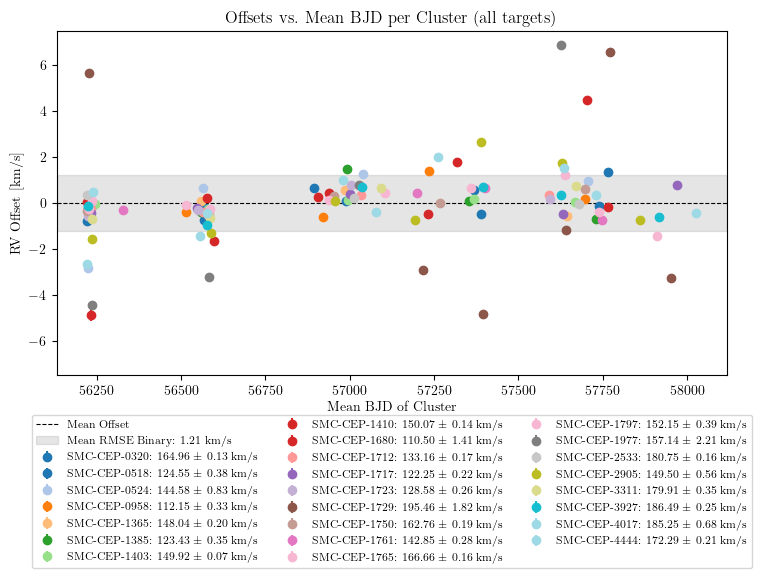

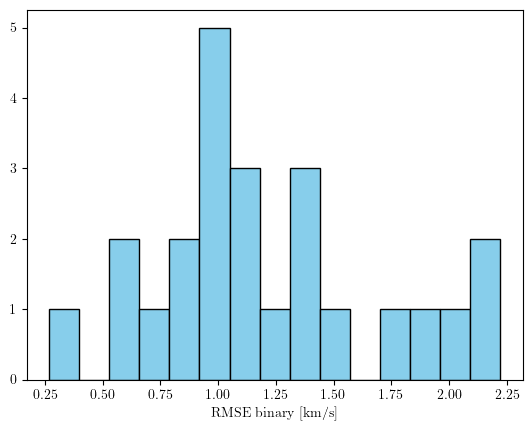

In [19]:
mean_rmse_binary_gieren = overview_gieren["rmse_binary"].mean()
print(f"Mean RMSE Binary: {mean_rmse_binary_gieren:.2f} km/s")
print(f"Median RMSE Binary: {overview_gieren['rmse_binary'].median():.2f} km/s")
print(f"Mean RMSE Single: {overview_gieren['rmse_single'].mean():.2f} km/s")

fig, ax = plot_offsets_vs_bjd(result_map_gieren, mean_rmse_binary_gieren)

fig, axs = plt.subplots()
axs.hist(
    overview_gieren["rmse_binary"],
    bins=15,
    color="skyblue",
    edgecolor="black",
)
axs.set_xlabel("RMSE binary [km/s]")

#### Run simulations to get the detectable binary ratio

Keplerian orbital solutions published in VELOCE DR1 are injected at the cluster mean epochs of each target
(with noise scaled by the per-cluster sample size) and flagged as detected when the resulting peak-to-peak
offset amplitude exceeds `thresh_sigma` times the sample mean binary RMSE. Running the same simulation with the
orbit amplitude set to zero (pure noise) gives the false-alarm probability of the threshold.

In [20]:
def keplerian_rv(coeff: np.ndarray, t: np.ndarray) -> np.ndarray:
    """Keplerian RV orbit in the VELOCE DR1 parametrization.

    ``coeff = [nu, pecc, T0, A, B]`` with ``nu = 1/P_orb`` [1/day],
    ``ecc = arctan(pecc)/pi + 0.5``, ``T0`` the periastron passage in orbital
    phase units, ``A = K cos(omega)`` and ``B = -K sin(omega)``.
    """
    nu, pecc, t0, a_coef, b_coef = np.asarray(coeff, dtype=float)
    ecc = np.arctan(pecc) / np.pi + 0.5
    mean_anomaly = 2.0 * np.pi * ((np.asarray(t, dtype=float) * nu - t0) % 1.0)
    # Solve Kepler's equation with Newton iterations
    ecc_anomaly = mean_anomaly.copy()
    for _ in range(100):
        delta = (ecc_anomaly - ecc * np.sin(ecc_anomaly) - mean_anomaly) / (
            1.0 - ecc * np.cos(ecc_anomaly)
        )
        ecc_anomaly -= delta
        if np.max(np.abs(delta)) < 1e-12:
            break
    true_anomaly = 2.0 * np.arctan2(
        np.sqrt(1.0 + ecc) * np.sin(ecc_anomaly / 2.0),
        np.sqrt(1.0 - ecc) * np.cos(ecc_anomaly / 2.0),
    )
    return a_coef * np.cos(true_anomaly) + b_coef * np.sin(true_anomaly) + ecc * a_coef


# Load the published VELOCE DR1 Keplerian orbits (last 5 coefficients)
veloce_orbits = {}
for orbit_file in sorted(veloce_orbits_folder.glob("*.fits")):
    with fits.open(orbit_file) as hdul:
        veloce_orbits[orbit_file.stem] = np.asarray(
            hdul["COEFF"].data["coeff"],
            dtype=float,
        )[-5:]
print(f"Loaded {len(veloce_orbits)} VELOCE orbits")


def simulate_target_detection(  # noqa: PLR0913
    orbit: np.ndarray,
    target_df: pd.DataFrame,
    rmse_fixed: float,
    thresh_sigma: float = 2.0,
    n_phase: int = 100,
    rng: np.random.Generator | None = None,
) -> tuple[int, float, np.ndarray, np.ndarray]:
    """Test the detectability of one orbit for one target."""
    coeff = orbit.copy()
    mean_bjd = target_df["BJD"].mean()
    bjd_clusters = target_df.groupby("CLUSTER_ID")["BJD"].mean().to_numpy()
    norm_bjd_clusters = bjd_clusters - mean_bjd
    counts_per_cluster = target_df.groupby("CLUSTER_ID").size().to_numpy()
    error_on_cluster = rmse_fixed / np.sqrt(counts_per_cluster)

    detected = 0
    ap2p_list = []
    t0_values = []
    for _ in range(n_phase):
        coeff[2] = rng.uniform(0, 1)  # random periastron phase
        t0_values.append(coeff[2])
        orbit_values = keplerian_rv(coeff, norm_bjd_clusters)
        orbit_observed = orbit_values + rng.normal(
            0,
            error_on_cluster,
            size=orbit_values.shape,
        )
        ap2p = np.ptp(orbit_observed)
        ap2p_list.append(ap2p)
        if ap2p > thresh_sigma * rmse_fixed:
            detected += 1

    return detected, detected / n_phase, np.array(ap2p_list), np.array(t0_values)

Loaded 28 VELOCE orbits


In [21]:
rng_fap = np.random.default_rng(1337)
rmse_fixed = mean_rmse_binary_gieren
thresh_sigma = 2.0
n_phase = 1000

total_detected = []
for orbit_name, orbit in veloce_orbits.items():
    detected_per_target = [
        simulate_target_detection(
            orbit,
            result["target_data"],
            rmse_fixed,
            thresh_sigma,
            n_phase,
            rng_fap,
        )[0]
        for result in result_map_gieren.values()
    ]
    total_detected.append(detected_per_target)
    print(
        f"Median detected {orbit_name}: {np.median(detected_per_target) / n_phase:.2%}"
    )

total_detected = np.array(total_detected)
print(f"Mean detected: {np.mean(total_detected / n_phase):.2%}")
print(
    f"Mean of median detected: {np.mean(np.median(total_detected, axis=1)) / n_phase:.2%}"
)
print(f"Median detected: {np.median(total_detected) / n_phase:.2%}")

# False-alarm probability: same simulation with the orbital signal turned off
total_fap = []
for orbit_name, orbit in veloce_orbits.items():
    orbit_null = orbit.copy()
    orbit_null[-2:] = 0.0  # A = B = 0 -> pure noise
    fap_per_target = [
        simulate_target_detection(
            orbit_null,
            result["target_data"],
            rmse_fixed,
            thresh_sigma,
            n_phase,
            rng_fap,
        )[0]
        for result in result_map_gieren.values()
    ]
    total_fap.append(fap_per_target)
total_fap = np.array(total_fap)
print(f"FAP (mean detected with no signal): {np.mean(total_fap / n_phase):.2%}")

Median detected ASAS_J064540+0330.4: 100.00%
Median detected ASAS_J084951-4627.2: 100.00%
Median detected ASAS_J100814-5856.6: 100.00%
Median detected ASAS_J174603-3528.1: 99.80%
Median detected DL_Cas: 100.00%
Median detected FF_Aql: 100.00%
Median detected FN_Vel: 100.00%
Median detected FO_Car: 100.00%
Median detected GX_Car: 100.00%
Median detected IT_Car: 100.00%
Median detected MU_Cep: 100.00%
Median detected MY_Pup: 15.15%
Median detected NT_Pup: 96.10%
Median detected R_Cru: 36.95%
Median detected SY_Nor: 100.00%
Median detected S_Mus: 100.00%
Median detected S_Sge: 100.00%
Median detected TX_Mon: 100.00%
Median detected U_Vul: 83.80%
Median detected V0407_Cas: 85.55%
Median detected V1334_Cyg: 100.00%
Median detected VY_Per: 99.65%
Median detected VZ_Pup: 73.00%
Median detected W_Sgr: 78.65%
Median detected XX_Cen: 100.00%
Median detected YZ_Car: 100.00%
Median detected Z_Lac: 100.00%
Median detected del_Cep: 68.60%
Mean detected: 90.14%
Mean of median detected: 90.62%
Median 

In [22]:
(0.866 * 33 + 9) / 258 * len(result_map_gieren)

3.495627906976744

In [23]:
len(result_map_gieren)

24

In [24]:
(7 / 26)

0.2692307692307692

Scatter threshold (4th largest): 4.66 km/s
Scatter threshold MIN (5th largest): 4.24 km/s
Targets above this threshold: ['SMC-CEP-1729', 'SMC-CEP-1977', 'SMC-CEP-1680', 'SMC-CEP-4017']


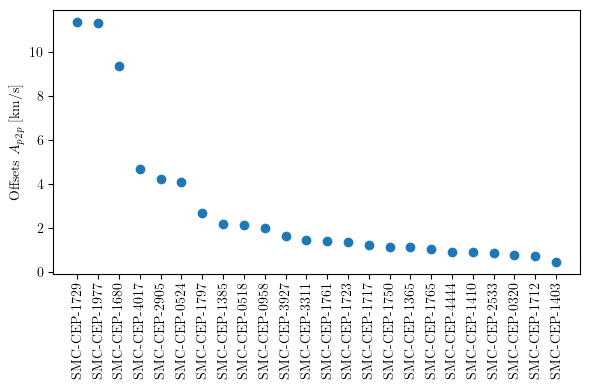

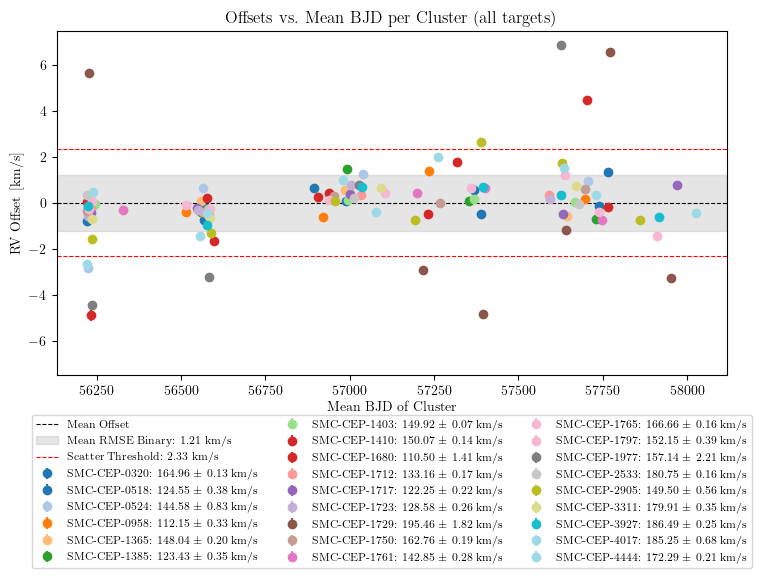

In [25]:
# Rank the targets by the peak-to-peak scatter of their per-cluster offsets and
# use the 4th largest as the binary-candidate threshold (as in the old analysis)
a_p2p = overview_gieren["offsets_p2p"].sort_values(ascending=False)
threshold_value = a_p2p.iloc[3]  # 4th largest
threshold_value_min = a_p2p.iloc[4]  # 5th largest
binary_candidates_gieren = a_p2p[a_p2p >= threshold_value].index.tolist()

print(f"Scatter threshold (4th largest): {threshold_value:.2f} km/s")
print(f"Scatter threshold MIN (5th largest): {threshold_value_min:.2f} km/s")
print("Targets above this threshold:", binary_candidates_gieren)

fig, axs = plt.subplots(figsize=(6, 4))
axs.plot(a_p2p.index, a_p2p.values, "o")
axs.tick_params(axis="x", labelrotation=90)
axs.set_ylabel(r"Offsets $A_{p2p}$ [km/s]")
fig.tight_layout()

fig, ax = plot_offsets_vs_bjd(
    result_map_gieren,
    mean_rmse_binary_gieren,
    threshold_value=threshold_value,
)

In [26]:
# Manually curated in the old analysis - revisit with the new numbers above
probable_binaries_gieren = [
    "SMC-CEP-1680",
    "SMC-CEP-1729",
    "SMC-CEP-1977",
    "SMC-CEP-4017",
    "SMC-CEP-2905",
    "SMC-CEP-0524",
]

#### Paper figure: cluster offsets vs epoch

Per-cluster systemic velocities (minus each target's mean offset) against the mean epoch of the cluster.
The scatter threshold $\sigma_{\rm cluster}$ is the RMS of the mean-subtracted offsets of the targets **not**
flagged as clear binaries (one degree of freedom lost per target mean). The legend reports
$f_{\sigma,\rm cluster} = \max|v_{\gamma,\rm cluster} - \overline{v_{\gamma,\rm cluster}}| / \sigma_{\rm cluster}$
for each target; squares mark the probable binaries.

Adopted scatter threshold: 0.84 km/s (95 offsets)
Mean STD of bins: 1.08 km/s
4th largest STD of bins: 1.66 km/s


,std_offsets,f_sigma_cluster
ID,,
SMC-CEP-1977,4.417548,8.234763
SMC-CEP-1729,4.448984,7.834547
SMC-CEP-1680,3.161632,5.837853
SMC-CEP-0524,1.652857,3.397531
SMC-CEP-4017,1.664201,3.180270
SMC-CEP-2905,1.482879,3.164032
SMC-CEP-1385,0.781322,1.767596
SMC-CEP-1797,0.875512,1.727725
SMC-CEP-0958,0.748210,1.670955


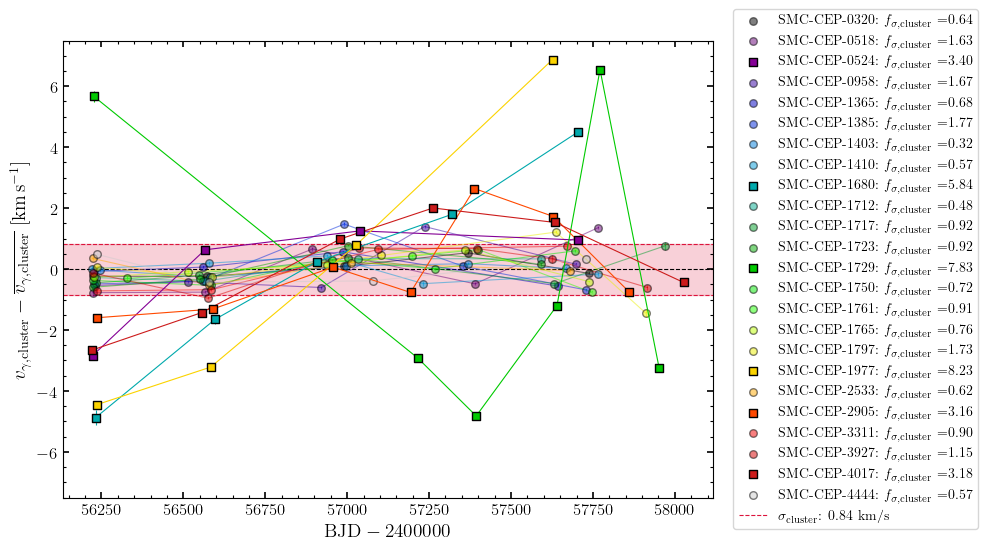

In [27]:
# Clearest binaries, excluded from the scatter-threshold computation
first_binaries_gieren = [
    "SMC-CEP-1680",
    "SMC-CEP-1729",
    "SMC-CEP-1977",
    "SMC-CEP-4017",
]

# Scatter threshold: RMS of the mean-subtracted offsets of the non-binary
# targets, with one dof lost per target mean
residual_offsets = []
n_targets_threshold = 0
for target_id, result in result_map_gieren.items():
    if target_id in first_binaries_gieren:
        continue
    residual_offsets.extend(result["offsets"] - np.mean(result["offsets"]))
    n_targets_threshold += 1
residual_offsets = np.asarray(residual_offsets)
sigma_cluster = float(
    np.sqrt(
        np.sum(residual_offsets**2) / (len(residual_offsets) - n_targets_threshold),
    ),
)
print(
    f"Adopted scatter threshold: {sigma_cluster:.2f} km/s "
    f"({len(residual_offsets)} offsets)",
)

cmap = plt.get_cmap("nipy_spectral", len(result_map_gieren))

fig, ax = plt.subplots(figsize=(10, 5.7))
f_sigma_rows = []
for idx, (target_id, result) in enumerate(result_map_gieren.items()):
    mean_bjd_per_cluster = (
        result["target_data"].groupby("CLUSTER_ID")["BJD"].mean().to_numpy()
    )
    offsets = result["offsets"]
    offsets_err = result["offsets_err"]
    mean_offset = np.mean(offsets)
    f_sigma = float(np.max(np.abs(offsets - mean_offset)) / sigma_cluster)
    f_sigma_rows.append(
        {
            "ID": target_id,
            "std_offsets": float(np.std(offsets - mean_offset)),
            "f_sigma_cluster": f_sigma,
        },
    )

    is_binary = target_id in probable_binaries_gieren
    alpha = 1 if is_binary else 0.5
    zorder = 5 if is_binary else 4

    ax.errorbar(
        mean_bjd_per_cluster,
        offsets - mean_offset,
        yerr=offsets_err,
        marker=",",
        markersize=5,
        color=cmap(idx),
        ls="-",
        lw=0.8,
        alpha=alpha,
        zorder=zorder,
    )
    ax.scatter(
        mean_bjd_per_cluster,
        offsets - mean_offset,
        s=30,
        color=cmap(idx),
        edgecolors="k",
        marker="s" if is_binary else "o",
        label=(f"{target_id}: " + r"$f_{\sigma, \rm{cluster}}=$" + f"{f_sigma:0.2f}"),
        alpha=alpha,
        zorder=zorder + 1,
    )

f_sigma_df = pd.DataFrame(f_sigma_rows).set_index("ID")
print(f"Mean STD of bins: {f_sigma_df['std_offsets'].mean():.2f} km/s")
print(
    "4th largest STD of bins: "
    f"{f_sigma_df['std_offsets'].nlargest(4).iloc[-1]:.2f} km/s",
)

ylim = ax.get_ylim()
max_ylim = max(abs(ylim[0]), abs(ylim[1]))
ax.set_ylim(-max_ylim, max_ylim)
ax.axhline(0, color="k", ls="--", lw=0.8)
xlim = ax.get_xlim()

ax.axhline(
    sigma_cluster,
    color="crimson",
    ls="--",
    lw=0.8,
    label=r"$\sigma_{\rm cluster}$" + f": {sigma_cluster:.2f} km/s",
)
ax.axhline(-sigma_cluster, color="crimson", ls="--", lw=0.8)
ax.fill_between(
    np.linspace(xlim[0], xlim[1], 100),
    -sigma_cluster,
    sigma_cluster,
    color="crimson",
    alpha=0.2,
)

vf.plot.format_xticks(
    ax,
    np.arange(56250, 60800, 250),
    np.arange(55250, 60800, 50),
    label_size=12,
)
vf.plot.format_yticks(
    ax,
    np.arange(-8, 8, 2),
    np.arange(-8, 8, 0.5),
    label_size=12,
)
ax.set_xlim(*xlim)
ax.set_ylim(-7.5, 7.5)

ax.set_xlabel(r"$\mathrm{BJD} - 2400000$", fontsize=14)
ax.set_ylabel(
    r"$v_{\gamma, \rm cluster} - \overline{v_{\gamma, \rm cluster}}$ [km\,s$^{-1}$]",
    fontsize=14,
)
ax.legend(bbox_to_anchor=(1.02, 0.5), loc="center left", fontsize=10, ncol=1)
fig.tight_layout()
fig.savefig(
    results_gieren_folder / "offsets_vs_mean_bjd_per_cluster_all_targets_v3.pdf",
    format="pdf",
)

f_sigma_df.sort_values("f_sigma_cluster", ascending=False)

#### Test MCMC results

In [28]:
comparison_mcmc_gieren = compare_map_mcmc_rmse(result_map_gieren)
comparison_mcmc_gieren.sort_values("diff", ascending=False).head(15)

,ID,model,rmse_map,rmse_mcmc,diff
25,SMC-CEP-1729,binary,2.158300,2.172923,0.014622
19,SMC-CEP-1712,binary,0.927416,0.933487,0.006071
45,SMC-CEP-4017,binary,1.900839,1.905255,0.004416
7,SMC-CEP-0958,binary,2.220428,2.223647,0.003219
16,SMC-CEP-1680,single,4.986243,4.988617,0.002375
36,SMC-CEP-2533,single,1.663983,1.664948,0.000966
10,SMC-CEP-1385,single,1.086785,1.087422,0.000638
17,SMC-CEP-1680,binary,1.436789,1.437346,0.000557
42,SMC-CEP-3927,single,1.390202,1.390559,0.000357
18,SMC-CEP-1712,single,0.746824,0.747152,0.000327


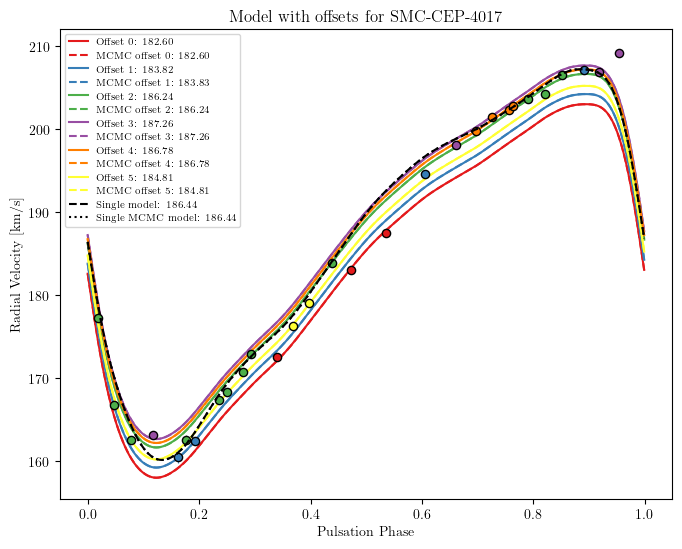

In [29]:
# Example target: MAP vs MCMC models
fig, axs = plot_target_fit(
    result_map_gieren["SMC-CEP-4017"],
    show_mcmc=True,
    figsize=(3.46 * 2, 3.46 * 1.618),
)

Confirmed singles: 1.04 1.71
 Confirmed binaries: 1.44 2.06
 All single models: 1.1636 4.00
 All binary models: 1.10 1.98

Final RMSE median: 1.1450, 90th percentile: 1.89


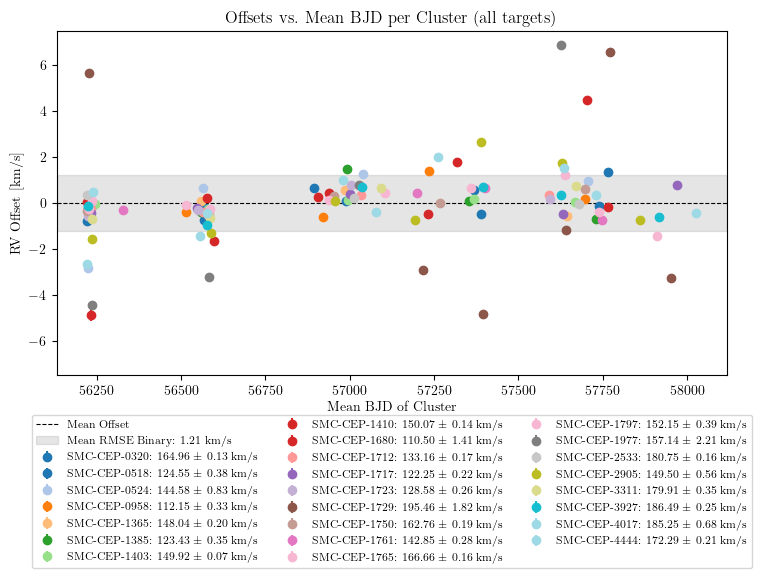

In [30]:
final_binaries_gieren = [
    "SMC-CEP-1680",
    "SMC-CEP-1729",
    "SMC-CEP-1977",
    "SMC-CEP-4017",
    "SMC-CEP-2905",
    # "SMC-CEP-0524",
]

is_multi_cluster = overview_gieren["n_clusters"] > 1
is_confirmed_binary = overview_gieren.index.isin(final_binaries_gieren)

rmse_single_confirmed = overview_gieren.loc[~is_confirmed_binary, "rmse_single"]
rmse_binary_confirmed = overview_gieren.loc[is_confirmed_binary, "rmse_binary"]
print(
    f"Confirmed singles: {rmse_single_confirmed.quantile(0.5):.2f} "
    f"{rmse_single_confirmed.quantile(0.9):.2f}\n",
    f"Confirmed binaries: {rmse_binary_confirmed.quantile(0.5):.2f} "
    f"{rmse_binary_confirmed.quantile(0.9):.2f}\n",
    f"All single models: {overview_gieren['rmse_single'].quantile(0.5):.4f} "
    f"{overview_gieren['rmse_single'].quantile(0.9):.2f}\n",
    f"All binary models: {overview_gieren.loc[is_multi_cluster, 'rmse_binary'].quantile(0.5):.2f} "
    f"{overview_gieren.loc[is_multi_cluster, 'rmse_binary'].quantile(0.9):.2f}\n",
)

final_rmse_gieren = np.where(
    is_confirmed_binary,
    overview_gieren["rmse_binary"],
    overview_gieren["rmse_single"],
)
print(
    f"Final RMSE median: {np.quantile(final_rmse_gieren, 0.5):.4f}, "
    f"90th percentile: {np.quantile(final_rmse_gieren, 0.9):.2f}",
)

fig, ax = plot_offsets_vs_bjd(
    result_map_gieren,
    overview_gieren["rmse_binary"].mean(),
)

#### Create table for paper

In [31]:
# SMC-CEP-0524 is kept with the single solution in the table (problematic
# binary fit, see the old analysis) but flagged as probable binary in the maps
table_gieren = build_paper_table(
    result_map_gieren,
    probable_binaries_gieren,
    table_binaries=set(probable_binaries_gieren) - {"SMC-CEP-0524"},
)
print(tabulate(table_gieren, tablefmt="latex_raw", headers="keys", showindex=False))

final_rmse_gieren = [
    result[
        f"rmse_{'binary' if tid in set(probable_binaries_gieren) - {'SMC-CEP-0524'} else 'single'}"
    ]
    for tid, result in result_map_gieren.items()
]
print(
    f"Final RMSE median: {np.quantile(final_rmse_gieren, 0.5):.2f}, "
    f"90th percentile: {np.quantile(final_rmse_gieren, 0.9):.2f}",
)

\begin{tabular}{lllrl}
\hline
 ID                    & mean_rv           & mean_rv_p2p   &   P2P & RMSE        \\
\hline
 SMC-CEP-0320          & 164.98 $\pm$ 0.01 & -             & 13.43 & 0.33 (2.4%) \\
 SMC-CEP-0518          & 124.65 $\pm$ 0.02 & -             & 52.72 & 1.40 (2.7%) \\
 SMC-CEP-0524          & 145.25 $\pm$ 0.02 & -             & 32.28 & 1.17 (3.6%) \\
 SMC-CEP-0958          & 112.32 $\pm$ 0.01 & -             & 55.64 & 2.13 (3.8%) \\
 SMC-CEP-1365          & 148.14 $\pm$ 0.01 & -             & 22.39 & 0.65 (2.9%) \\
 SMC-CEP-1385          & 123.70 $\pm$ 0.02 & -             & 36.03 & 1.09 (3.0%) \\
 SMC-CEP-1403          & 149.95 $\pm$ 0.01 & -             & 32.27 & 0.68 (2.1%) \\
 SMC-CEP-1410          & 150.14 $\pm$ 0.03 & -             & 47.47 & 1.88 (4.0%) \\
 SMC-CEP-1680$\dagger$ & 110.50 $\pm$ 1.41 & 9.37          & 42.61 & 1.44 (3.4%) \\
 SMC-CEP-1712          & 133.32 $\pm$ 0.01 & -             & 27.96 & 0.75 (2.7%) \\
 SMC-CEP-1717          & 122.40 $\pm$ 0

#### Plot average velocity over the sky

For confirmed non-binaries we just take the (single-fit) `v_gamma`, whereas for the probable binaries we take
the mean of the per-cluster offsets and its standard error.

In [32]:
vgamma_gieren_df = gieren_2018_targets.merge(
    build_mean_rv_df(result_map_gieren, probable_binaries_gieren),
    on="ID",
    how="inner",
)

mean_rv_all = vgamma_gieren_df["mean_rv"].mean()
vgamma_gieren_df["delta_rv"] = vgamma_gieren_df["mean_rv"] - mean_rv_all

print(f"Mean RV all targets: {mean_rv_all:.2f} km/s")
print(f"Median RV all targets: {vgamma_gieren_df['mean_rv'].median():.2f} km/s")
print(
    "Error on Mean RV all targets: "
    f"{vgamma_gieren_df['mean_rv'].std() / np.sqrt(len(vgamma_gieren_df) - 1):.2f} km/s",
)
weights = 1 / vgamma_gieren_df["mean_rv_err"] ** 2
weighted_mean_rv = np.average(vgamma_gieren_df["mean_rv"], weights=weights)
print(f"Weighted Mean RV all targets: {weighted_mean_rv:.2f} km/s")
v1 = np.sum(weights)
v2 = np.sum(weights**2)
weighted_mean_err = np.sqrt(
    np.sum(vgamma_gieren_df["delta_rv"] ** 2 * weights) / (v1 - v2 / v1),
) / np.sqrt(len(vgamma_gieren_df) - 1)
print(f"Error on weighted mean RV all targets: {weighted_mean_err:.2f} km/s")
print(f"STD RV all targets: {vgamma_gieren_df['mean_rv'].std():.2f} km/s")

Mean RV all targets: 151.88 km/s
Median RV all targets: 150.04 km/s
Error on Mean RV all targets: 5.06 km/s
Weighted Mean RV all targets: 152.47 km/s
Error on weighted mean RV all targets: 4.54 km/s
STD RV all targets: 24.27 km/s


 [astropy.io.fits.verify]


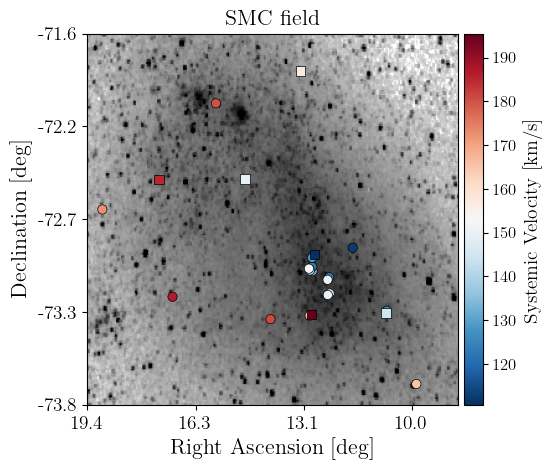

In [33]:
fig, ax = plot_vgamma_sky(
    vgamma_gieren_df,
    probable_binaries_gieren,
    position="SMC",
    width=3.5 * u.deg,
    height=2.2 * u.deg,
    pixels=(350, 300),
    xlim=(0, 300),
    save_path=results_gieren_folder / "vgamma_map_gieren_2018.pdf",
)

# Storm et al. 2011 (LMC)

In [34]:
storm_2011_data = pd.read_csv(
    storm_2011_folder / "table2.dat",
    header=None,
    names=["ID", "BJD", "RV"],
    dtype={"ID": str, "BJD": np.float64, "RV": np.float64},
    sep="\\s+",
)
storm_2011_data["e_RV"] = 0.1  # Constant error of 0.1 km/s as in the paper
storm_2011_data["BJD"] -= 2400000.0

# Remove clear outliers:
# - HV873: strange point at index 12
# - HV878: strange point at index 87
# Uncertain to remove index 506 from U1 (could be sign of binary)
storm_2011_data = storm_2011_data.drop([12, 87]).reset_index(drop=True)

storm_2011_periods = pd.read_fwf(
    storm_2011_folder / "table3.dat",
    header=None,
    names=[
        "ID",
        "logP",
        "d",
        "d_err",
        "dist_mod",
        "dist_mod_err",
        "vmag",
        "imag",
        "jmag",
        "hmag",
        "kmag",
        "wvi",
        "wjk",
        "eb-v",
        "dphi",
        "ddsit_mod",
    ],
    usecols=["ID", "logP"],
    dtype={"ID": str, "logP": np.float64},
)
storm_2011_periods["P"] = 10 ** storm_2011_periods["logP"]

print(f"{storm_2011_data['ID'].nunique()} targets, {len(storm_2011_data)} epochs")
storm_2011_periods

22 targets, 507 epochs


,ID,logP,P
0,HV12199,0.421469,2.639180
1,HV12203,0.470427,2.954112
2,HV12202,0.491519,3.101123
3,HV12197,0.497456,3.143808
4,HV12204,0.536402,3.438761
5,HV12198,0.546887,3.522792
6,HV6093,0.679885,4.785034
7,HV914,0.837489,6.878425
8,HV2405,0.840331,6.923585
9,HV12452,0.941457,8.738905


In [35]:
# Target coordinates from Simbad (cached to CSV to avoid repeated queries)
storm_coords_cache = results_storm_folder / "storm_2011_simbad_coordinates.csv"
if storm_coords_cache.exists():
    storm_coords = pd.read_csv(storm_coords_cache)
else:
    from astroquery.simbad import Simbad

    rows = []
    for target in storm_2011_periods["ID"]:
        query_name = "OGLE LMC-CEP-79" if target == "U1" else target
        try:
            result = Simbad.query_object(query_name)
        except Exception as exc:  # noqa: BLE001
            print(f"Error resolving {target}: {exc}")
            result = None
        if result is None:
            print(f"No result for {target}")
            rows.append({"ID": target, "RAdeg": np.nan, "DEdeg": np.nan})
            continue
        coord = SkyCoord(
            ra=result["ra"][0],
            dec=result["dec"][0],
            unit=(u.deg, u.deg),
        )
        rows.append({"ID": target, "RAdeg": coord.ra.deg, "DEdeg": coord.dec.deg})
    storm_coords = pd.DataFrame(rows)
    storm_coords.to_csv(storm_coords_cache, index=False)

storm_2011_periods = storm_2011_periods.merge(storm_coords, on="ID", how="left")
storm_2011_periods

,ID,logP,P,RAdeg,DEdeg
0,HV12199,0.421469,2.639180,78.329167,-65.491667
1,HV12203,0.470427,2.954112,78.416667,-65.493333
2,HV12202,0.491519,3.101123,78.412500,-65.483333
3,HV12197,0.497456,3.143808,78.304167,-65.513333
4,HV12204,0.536402,3.438761,78.491142,-65.477593
5,HV12198,0.546887,3.522792,78.361122,-65.451370
6,HV6093,0.679885,4.785034,89.445186,-68.684524
7,HV914,0.837489,6.878425,78.195978,-69.102467
8,HV2405,0.840331,6.923585,78.673146,-70.708912
9,HV12452,0.941457,8.738905,72.213925,-69.356322


### Clustering the data

In [36]:
clustered_storm_list = []
for target_id, group in storm_2011_data.groupby("ID"):
    if target_id not in storm_2011_periods["ID"].to_numpy():
        print(f"Skipping {target_id} - no period found in Storm 2011 data.")
        continue
    period = storm_2011_periods.loc[
        storm_2011_periods["ID"] == target_id,
        "P",
    ].to_numpy()[0]
    target_data = group.copy()
    baseline = target_data["BJD"].max() - target_data["BJD"].min()
    bandwidth = clustering_bandwidth(period)
    target_data["CLUSTER_ID"] = cluster_data(
        target_data,
        bandwidth=bandwidth,
        plot_folder=results_storm_folder / "clustering",
    )
    print(
        target_id,
        baseline,
        period,
        bandwidth,
        target_data["CLUSTER_ID"].nunique(),
    )
    clustered_storm_list.append(target_data)

clustered_storm = pd.concat(clustered_storm_list, ignore_index=True)
clustered_storm

HV1005 728.9912999998778 18.715826046235783 80.0 3
HV1006 14.953499999828637 14.216281026938594 80.0 1
HV1023 838.841599999927 26.560423776471207 80.0 3
HV12452 15.023300000000745 8.738904633993629 80.0 1
HV12505 14.95380000025034 14.391796186610344 80.0 1
HV12717 1052.0797000001185 8.843577783506003 80.0 4
HV2282 14.990199999883771 14.67695626144774 80.0 1
HV2369 763.9213999998756 48.37778721666144 100.0 3


HV2405 14.004499999806285 6.923584548000657 80.0 1
HV2527 12.88510000007227 12.949440366474764 80.0 1
HV2538 12.916999999899417 13.871326686135024 80.0 1
HV2549 15.006199999712408 16.228896853362926 80.0 1
HV5655 14.953600000124425 14.212058942636437 80.0 1
HV6093 14.981699999887496 4.785033691520559 80.0 1
HV873 818.8557000001892 34.45966094269771 100.0 3
HV876 838.7886000000872 22.71653038359725 80.0 3
HV877 786.9012000001967 45.20796936583076 100.0 2
HV878 813.8163000000641 23.304779597839282 80.0 3
HV881 838.845100000035 35.71247916340949 100.0 3
HV900 845.8011000002734 47.38457612161049 100.0 3
HV914 1058.1547999996692 6.878424901136654 80.0 4
U1 810.812799999956 22.54747946154416 80.0 3


,ID,BJD,RV,e_RV,CLUSTER_ID
0,HV1005,53701.7579,265.20,0.1,0
1,HV1005,53702.7823,270.17,0.1,0
2,HV1005,53703.7871,275.01,0.1,0
3,HV1005,53704.7855,279.99,0.1,0
4,HV1005,53705.7773,285.04,0.1,0
...,...,...,...,...,...
502,U1,54101.8270,281.28,0.1,1
503,U1,54124.6136,282.85,0.1,1
504,U1,54364.7819,251.71,0.1,2
505,U1,54488.5945,270.64,0.1,2


### Fit data

In [37]:
result_map_storm = {}
storm_ids = clustered_storm["ID"].unique()
for i, target_id in enumerate(tqdm(storm_ids)):
    log_p = storm_2011_periods.loc[
        storm_2011_periods["ID"] == target_id,
        "logP",
    ].to_numpy()[0]
    result_map_storm[target_id] = fit_target(
        target_id,
        clustered_storm,
        log_p,
        results_folder=results_storm_folder
        / f"fit_results_sigma_model_{sigma_model:.3f}",
        read_from_saved=read_from_saved,
    )

overview_storm = results_overview(result_map_storm)
overview_storm

  0%|          | 0/22 [00:00<?, ?it/s]

,log_P,P,n_rv,n_clusters,rmse_single,rmse_binary,delta_phi,offsets_p2p,norm_chi2_offsets,compatible_95,compatible_99,mean_offset,mean_offset_err,weighted_mean_offset
ID,,,,,,,,,,,,,,
HV1005,1.272209,18.715826,20,3,2.846010,0.825829,0.774904,11.335346,944.034199,False,False,273.671000,2.674603,273.862583
HV1006,1.152786,14.216281,16,1,0.781355,0.781355,0.042096,0.000000,NaN,True,True,271.746313,0.025549,271.746313
HV1023,1.424235,26.560424,23,3,2.447473,1.976301,0.671546,6.450444,1203.181061,False,False,292.356557,1.648396,291.447264
HV12452,0.941457,8.738905,25,1,0.626256,0.626256,0.951562,0.000000,NaN,True,True,234.229273,0.020034,234.229273
HV12505,1.158115,14.391796,17,1,1.033753,1.033753,0.647251,0.000000,NaN,True,True,284.727028,0.025163,284.727028
HV12717,0.946628,8.843578,35,4,0.806849,0.769204,0.905209,1.063567,137.721584,False,False,258.175287,0.190001,258.231405
HV2282,1.166636,14.676956,17,1,0.674488,0.674488,0.812486,0.000000,NaN,True,True,256.788329,0.024531,256.788329
HV2369,1.684646,48.377787,26,3,0.693993,0.730447,0.105813,0.533326,9.156526,False,False,308.124984,0.127652,308.049687
HV2405,0.840331,6.923585,21,1,0.967116,0.967116,0.190116,0.000000,NaN,True,True,210.191902,0.023296,210.191902


In [38]:
target_id = "HV914"

In [39]:
result_map_storm["HV914"]

{'target_id': 'HV914',
 'log_P': 0.837489,
 'P': 6.878424901136654,
 'n_clusters': 4,
 'main_cluster_id': 0,
 'mean_bjd_ref': 51558.65293750001,
 'sigma_model': 0.0,
 'target_data':         ID         BJD      RV  e_RV  CLUSTER_ID  PULS_PHASE
 435  HV914  51545.6641  279.99   0.1           0    0.111655
 436  HV914  51546.6888  255.89   0.1           0    0.260628
 437  HV914  51547.6648  241.89   0.1           0    0.402521
 438  HV914  51548.6395  248.69   0.1           0    0.544225
 439  HV914  51549.6368  256.37   0.1           0    0.689215
 440  HV914  51550.5473  263.29   0.1           0    0.821585
 441  HV914  51551.6352  271.55   0.1           0    0.979746
 442  HV914  51552.6897  281.07   0.1           0    0.133052
 443  HV914  51564.6424  265.80   0.1           0    0.870761
 444  HV914  51565.6460  272.99   0.1           0    0.016666
 445  HV914  51566.7188  279.45   0.1           0    0.172632
 446  HV914  51567.6591  243.24   0.1           0    0.309335
 447  HV914  

#### Specific fits

**HV877**: remove what looks like a clear outlier — worth the change, makes a better fit.

**HV1023**: possible outlier — the fit statistics do not improve much, so the default fit is kept.

Note on HV2405: dividing the data was attempted in the old analysis, but the data were collected over two
consecutive pulsation cycles and no particular trend could be noticed (probably modulation + other issues).

In [40]:
# HV877: row 349 is the clear outlier identified in the old analysis.
# Inspect it before dropping.
target_data_hv877 = clustered_storm[clustered_storm["ID"] == "HV877"]
display(target_data_hv877.loc[[349]])

log_p_hv877 = storm_2011_periods.loc[
    storm_2011_periods["ID"] == "HV877",
    "logP",
].to_numpy()[0]
result_hv877 = fit_target(
    "HV877",
    target_data_hv877.drop(349),
    log_p_hv877,
    results_folder=results_storm_folder
    / f"fit_results_sigma_model_{sigma_model:.3f}"
    / "map_results_specific",
    read_from_saved=read_from_saved,
)

# Update the main results with the specific fit
result_map_storm["HV877"] = result_hv877
overview_storm = results_overview(result_map_storm)

,ID,BJD,RV,e_RV,CLUSTER_ID
349,HV877,54046.7077,301.32,0.1,1


#### Analyze results

Confirmed singles: 0.77 1.19
 Confirmed binaries: 0.83 1.01
 All single models: 0.7941 1.91
 All binary models: 0.80 1.05

Final RMSE median: 0.7755, 90th percentile: 1.16


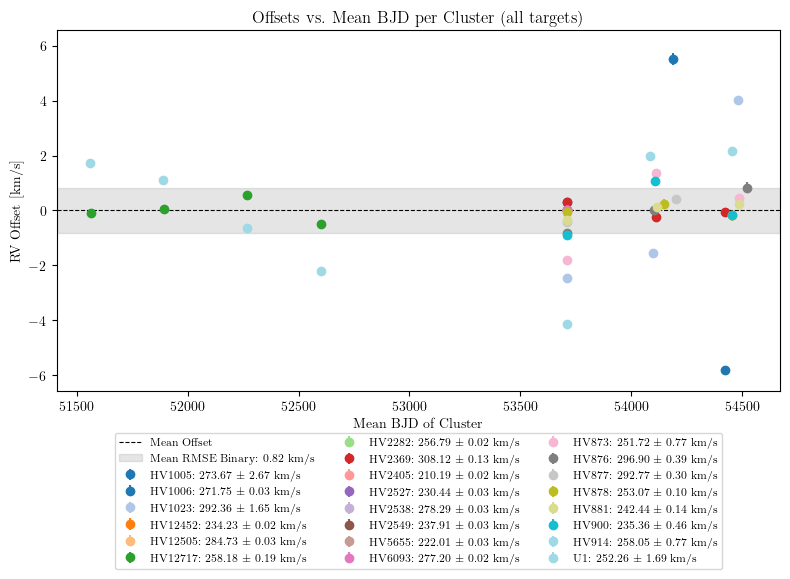

In [41]:
probable_binaries_storm = ["HV914", "U1", "HV1005"]

is_multi_cluster = overview_storm["n_clusters"] > 1
is_confirmed_binary = overview_storm.index.isin(probable_binaries_storm)

rmse_single_confirmed = overview_storm.loc[~is_confirmed_binary, "rmse_single"]
rmse_binary_confirmed = overview_storm.loc[is_confirmed_binary, "rmse_binary"]
print(
    f"Confirmed singles: {rmse_single_confirmed.quantile(0.5):.2f} "
    f"{rmse_single_confirmed.quantile(0.9):.2f}\n",
    f"Confirmed binaries: {rmse_binary_confirmed.quantile(0.5):.2f} "
    f"{rmse_binary_confirmed.quantile(0.9):.2f}\n",
    f"All single models: {overview_storm['rmse_single'].quantile(0.5):.4f} "
    f"{overview_storm['rmse_single'].quantile(0.9):.2f}\n",
    f"All binary models: {overview_storm.loc[is_multi_cluster, 'rmse_binary'].quantile(0.5):.2f} "
    f"{overview_storm.loc[is_multi_cluster, 'rmse_binary'].quantile(0.9):.2f}\n",
)

final_rmse_storm = np.where(
    is_confirmed_binary,
    overview_storm["rmse_binary"],
    overview_storm["rmse_single"],
)
print(
    f"Final RMSE median: {np.quantile(final_rmse_storm, 0.5):.4f}, "
    f"90th percentile: {np.quantile(final_rmse_storm, 0.9):.2f}",
)

fig, ax = plot_offsets_vs_bjd(
    result_map_storm,
    overview_storm["rmse_binary"].mean(),
)

#### Test MCMC results

In [42]:
comparison_mcmc_storm = compare_map_mcmc_rmse(result_map_storm)
comparison_mcmc_storm.sort_values("diff", ascending=False).head(15)

,ID,model,rmse_map,rmse_mcmc,diff
16,HV5655,single,0.611881,0.613952,2.070829e-03
14,HV2538,single,0.732863,0.733306,4.426187e-04
32,U1,single,1.911976,1.912315,3.388637e-04
29,HV900,binary,0.290779,0.290823,4.455118e-05
0,HV1005,single,2.846010,2.846049,3.856086e-05
24,HV878,single,0.678344,0.678374,2.984520e-05
23,HV877,binary,0.237748,0.237773,2.594693e-05
20,HV876,single,0.819645,0.819661,1.614131e-05
33,U1,binary,0.593458,0.593468,1.013301e-05
21,HV876,binary,0.862436,0.862446,9.825194e-06


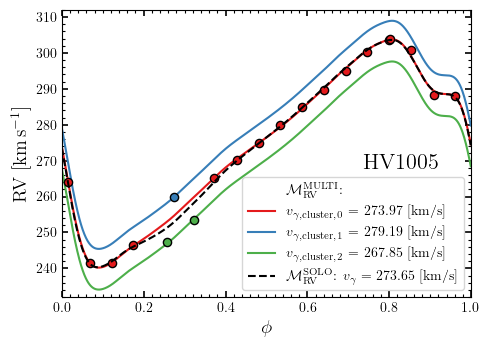

In [43]:
target_id = "HV1005"
fig, axs = plot_target_fit_paper(result_map_storm, target_id, figsize=(5, 5 / 1.4))
fig.savefig(
    results_storm_folder
    / f"fit_results_sigma_model_{sigma_model:.3f}"
    / f"{target_id}_PC_fit.pdf",
    format="pdf",
)

#### Create table for paper

In [44]:
table_storm = build_paper_table(result_map_storm, probable_binaries_storm)
print(
    tabulate(
        table_storm.sort_values(by="ID"),
        tablefmt="latex_raw",
        headers="keys",
        showindex=False,
    )
)

\begin{tabular}{lllrl}
\hline
 ID              & mean_rv           & mean_rv_p2p   &   P2P & RMSE        \\
\hline
 HV1005$\dagger$ & 273.67 $\pm$ 2.67 & 11.34         & 63.54 & 0.83 (1.3%) \\
 HV1006          & 271.75 $\pm$ 0.03 & -             & 52.71 & 0.78 (1.5%) \\
 HV1023          & 291.64 $\pm$ 0.02 & -             & 53.14 & 2.45 (4.6%) \\
 HV12452         & 234.23 $\pm$ 0.02 & -             & 38.87 & 0.63 (1.6%) \\
 HV12505         & 284.73 $\pm$ 0.03 & -             & 53.34 & 1.03 (1.9%) \\
 HV12717         & 258.23 $\pm$ 0.02 & -             & 34.96 & 0.81 (2.3%) \\
 HV2282          & 256.79 $\pm$ 0.02 & -             & 54.57 & 0.67 (1.2%) \\
 HV2369          & 308.11 $\pm$ 0.03 & -             & 50.3  & 0.69 (1.4%) \\
 HV2405          & 210.19 $\pm$ 0.02 & -             & 26.73 & 0.97 (3.6%) \\
 HV2527          & 230.44 $\pm$ 0.03 & -             & 53.11 & 0.77 (1.4%) \\
 HV2538          & 278.29 $\pm$ 0.03 & -             & 33.04 & 0.73 (2.2%) \\
 HV2549          & 237.91 $

#### Plot average velocity over the sky

For confirmed non-binaries we just take the (single-fit) `v_gamma`, whereas for the probable binaries we take
the mean of the per-cluster offsets and its standard error.

Mean RV all targets: 259.85 km/s
Median RV all targets: 257.42 km/s
STD RV all targets: 26.16 km/s


 [astropy.io.fits.verify]


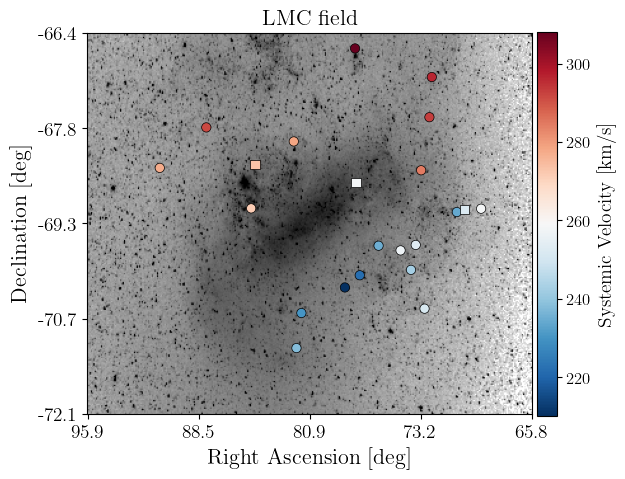

In [45]:
vgamma_storm_df = storm_2011_periods.merge(
    build_mean_rv_df(result_map_storm, probable_binaries_storm),
    on="ID",
    how="inner",
)

mean_rv_all_storm = vgamma_storm_df["mean_rv"].mean()
print(f"Mean RV all targets: {mean_rv_all_storm:.2f} km/s")
print(f"Median RV all targets: {vgamma_storm_df['mean_rv'].median():.2f} km/s")
print(f"STD RV all targets: {vgamma_storm_df['mean_rv'].std():.2f} km/s")

fig, ax = plot_vgamma_sky(
    vgamma_storm_df,
    probable_binaries_storm,
    position="LMC",
    width=9.2 * u.deg,
    height=5.8 * u.deg,
    save_path=results_storm_folder / "vgamma_map_storm_2011.pdf",
)

# Plot comparison with priors

The fitted (posterior-median) PC coefficients of both Magellanic Cloud samples are compared against the VELOCE
training coefficients the 7-D KDE prior was fitted to (black points). Circles: single fits; squares: targets
opted for the binary solution.

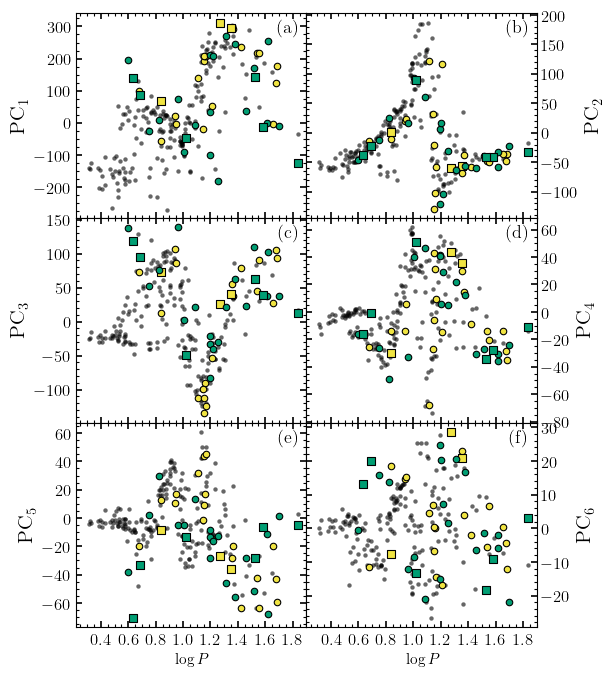

In [46]:
def collect_fit_points(result_map: dict, probable_binaries: list[str]) -> pd.DataFrame:
    """Posterior-median PCs of every target vs its log_P."""
    rows = []
    for target_id, result in result_map.items():
        which = "binary" if target_id in probable_binaries else "single"
        median = result[f"summary_{which}"]["median"]
        rows.append(
            {
                "ID": target_id,
                "log_P": result["log_P"],
                "binary": which == "binary",
                **{pc: median.loc[pc] for pc in pc_names_model},
            },
        )
    return pd.DataFrame(rows)


fit_points = pd.concat(
    [
        collect_fit_points(result_map_gieren, probable_binaries_gieren).assign(
            sample="SMC",
        ),
        collect_fit_points(result_map_storm, probable_binaries_storm).assign(
            sample="LMC",
        ),
    ],
    ignore_index=True,
)

# VELOCE training coefficients: the sample the 7-D KDE prior was fitted to
train_components_df = coefficients_df[coefficients_df["SET"] == "train"]

sample_colors = {"SMC": color_safe["light_green"], "LMC": color_safe["yellow"]}

fig, axs = plt.subplots(
    3,
    2,
    sharex=True,
    gridspec_kw={"hspace": 0, "wspace": 0},
)
image_factor = 1.8
width = 3.46 * image_factor
fig.set_size_inches(width, width * 1.618 / 2 * 3 / 2.2)

for i, (pc_kde, pc_model) in enumerate(zip(pc_names_kde, pc_names_model, strict=True)):
    ax = axs.flat[i]
    ax.text(
        0.97,
        0.97,
        f"({'abcdef'[i]})",
        transform=ax.transAxes,
        fontsize=label_size + 2,
        ha="right",
        va="top",
    )
    if i % 2 == 1:
        ax.yaxis.set_label_position("right")
        ax.yaxis.tick_right()

    # VELOCE training sample (the KDE prior was fitted to these points)
    ax.scatter(
        train_components_df["LOG_P"],
        train_components_df[pc_kde],
        c=color_safe["black"],
        s=10,
        marker="o",
        lw=0,
        alpha=0.6,
        zorder=2,
        label="VELOCE train" if i == 0 else None,
    )

    for sample_name, sample_points in fit_points.groupby("sample"):
        singles = sample_points[~sample_points["binary"]]
        binaries = sample_points[sample_points["binary"]]
        ax.scatter(
            singles["log_P"],
            singles[pc_model],
            c=sample_colors[sample_name],
            s=22,
            marker="o",
            edgecolors="k",
            lw=0.8,
            zorder=3,
            label=sample_name if i == 0 else None,
        )
        ax.scatter(
            binaries["log_P"],
            binaries[pc_model],
            c=sample_colors[sample_name],
            s=26,
            marker="s",
            edgecolors="k",
            lw=0.8,
            zorder=3,
        )

    ax.set_ylabel(rf"$\rm PC_{i + 1}$", fontsize=label_size)
    ylims = ax.get_ylim()
    if i == 0:
        y_ticks = np.arange(-500, 500, 100)
        y_ticks_minor = np.arange(-500, 500, 25)
        ylims = (ylims[0] + 5, ylims[1])
    elif i in {1, 2}:
        y_ticks = np.arange(-200, 400, 50)
        y_ticks_minor = np.arange(-200, 400, 10)
    elif i in {3, 4}:
        y_ticks = np.arange(-200, 200, 20)
        y_ticks_minor = np.arange(-200, 200, 5)
    elif i == 5:  # noqa: PLR2004
        y_ticks = np.arange(-100, 100, 10)
        y_ticks_minor = np.arange(-100, 100, 2)
        # ylim = (ylims[0], ylims[1] )
    else:
        pass

    vf.plots_utils.format_yticks(ax, y_ticks, y_ticks_minor, label_size=12)
    ax.set_ylim(*ylims)
    ax.set_ylabel(r"$\rm{PC_" + str(i + 1) + "}$", fontsize=15)
    x_ticks = np.arange(0.2, 2, 0.2)
    x_ticks_minor = np.arange(0.2, 2, 0.05)
    xlims = [0.22, 1.9]
    vf.plots_utils.format_xticks(ax, x_ticks, x_ticks_minor, label_size=12)
    ax.set_xlim(*xlims)
for ax in axs[-1]:
    ax.set_xlabel(r"$\log P$", fontsize=label_size)

# axs.flat[0].legend(fontsize=label_size - 2, loc="lower left")
fig.tight_layout()
fig.savefig(mc_results_dir / "kde_components_MC.pdf", format="pdf")

# End

In [53]:
def build_cds_table(
    result_map: dict,
    probable_binaries: list[str],
    table_binaries: set[str] | None = None,
) -> pd.DataFrame:
    """Per-target summary table for the paper.

    ``table_binaries`` allows overriding which targets are shown with the
    binary solution in the table (defaults to ``probable_binaries``).
    """
    if table_binaries is None:
        table_binaries = set(probable_binaries)
    rows = []
    for target_id, result in result_map.items():
        is_binary = target_id in table_binaries
        which = "binary" if is_binary else "single"
        p2p = model_p2p(result, which=which)
        rmse = result[f"rmse_{which}"]
        if is_binary:
            mean_rv = result["mean_offset"]
            mean_rv_err = result["mean_offset_err"]
            rv_p2p = f"{np.ptp(result['offsets']):.2f}"
        else:
            mask = result["best_single"].model.layout.mask("offsets")
            mean_rv = float(result["summary_single"]["mean"].to_numpy()[mask][0])
            mean_rv_err = float(result["summary_single"]["std"].to_numpy()[mask][0])
            rv_p2p = np.nan
        rows.append(
            {
                "ID": target_id, #+ (r"$\dagger$" if is_binary else ""),
                "mean_rv": mean_rv,
                "mean_rv_err": mean_rv_err,
                "mean_rv_p2p": rv_p2p,
                "P2P": p2p,
                "RMSE": rmse,# ({rmse / p2p * 100:.1f}%)",
                "RMSE_rel": 100.0 * rmse / p2p,  # computed before rounding
                "SB1": "Y" if is_binary else "N",  # replaces the dagger
            },
        )
    return pd.DataFrame(rows)

In [54]:
table_gieren_cds = build_cds_table(
    result_map_gieren,
    probable_binaries_gieren,
    table_binaries=set(probable_binaries_gieren) - {"SMC-CEP-0524"},
)

In [55]:
table_storm_cds = build_cds_table(result_map_storm, probable_binaries_storm)

In [56]:
table_storm_cds

,ID,mean_rv,mean_rv_err,mean_rv_p2p,P2P,RMSE,RMSE_rel,SB1
0,HV1005,273.671000,2.674603,11.34,63.544802,0.825829,1.299601,Y
1,HV1006,271.746313,0.025549,NaN,52.712829,0.781355,1.482286,N
2,HV1023,291.635036,0.022188,NaN,53.142543,2.447473,4.605487,N
3,HV12452,234.229273,0.020034,NaN,38.867143,0.626256,1.611273,N
4,HV12505,284.727028,0.025163,NaN,53.335756,1.033753,1.938199,N
5,HV12717,258.226926,0.017655,NaN,34.956631,0.806849,2.308142,N
6,HV2282,256.788329,0.024531,NaN,54.565009,0.674488,1.236119,N
7,HV2369,308.110393,0.025589,NaN,50.300799,0.693993,1.379685,N
8,HV2405,210.191902,0.023296,NaN,26.733803,0.967116,3.617578,N
9,HV2527,230.436329,0.026735,NaN,53.107287,0.769733,1.449392,N


In [59]:
def write_tableb1(
    table_storm: pd.DataFrame,
    table_gieren: pd.DataFrame,
    path: str = "tableb1.csv",
) -> pd.DataFrame:
    """Stack the LMC (Storm+2011) and SMC (Gieren+2018) tables, in the
    order of Table B.1, and save them as one CSV for make_cds_tables.py."""
    lmc = table_storm.assign(Gal="LMC", Ref="Storm+2011")
    smc = table_gieren.assign(Gal="SMC", Ref="Gieren+2018")
    tab = pd.concat([lmc, smc], ignore_index=True)
    tab = tab[["ID", "Gal", "Ref", "mean_rv", "mean_rv_err", "mean_rv_p2p",
               "P2P", "RMSE", "RMSE_rel", "SB1"]]
    if tab["ID"].duplicated().any():
        raise ValueError(f"duplicate IDs: {tab['ID'][tab['ID'].duplicated()]}")
    # full precision; NaN written as an empty field (read back as masked)
    tab.to_csv(loading_dir/path, index=False, na_rep="")
    return tab

In [60]:
write_tableb1(table_gieren=table_gieren_cds, table_storm=table_storm_cds)

,ID,Gal,Ref,mean_rv,mean_rv_err,mean_rv_p2p,P2P,RMSE,RMSE_rel,SB1
0,HV1005,LMC,Storm+2011,273.671000,2.674603,11.34,63.544802,0.825829,1.299601,Y
1,HV1006,LMC,Storm+2011,271.746313,0.025549,NaN,52.712829,0.781355,1.482286,N
2,HV1023,LMC,Storm+2011,291.635036,0.022188,NaN,53.142543,2.447473,4.605487,N
3,HV12452,LMC,Storm+2011,234.229273,0.020034,NaN,38.867143,0.626256,1.611273,N
4,HV12505,LMC,Storm+2011,284.727028,0.025163,NaN,53.335756,1.033753,1.938199,N
5,HV12717,LMC,Storm+2011,258.226926,0.017655,NaN,34.956631,0.806849,2.308142,N
6,HV2282,LMC,Storm+2011,256.788329,0.024531,NaN,54.565009,0.674488,1.236119,N
7,HV2369,LMC,Storm+2011,308.110393,0.025589,NaN,50.300799,0.693993,1.379685,N
8,HV2405,LMC,Storm+2011,210.191902,0.023296,NaN,26.733803,0.967116,3.617578,N
9,HV2527,LMC,Storm+2011,230.436329,0.026735,NaN,53.107287,0.769733,1.449392,N
